# Saiyam  23csu273
# Sarthak 23csu284
# Sahil 23csu271

# Explainable Multimodal Skin Lesion Classification — DERM 12345 & BCN20000

### End-to-End Machine Learning + Deep Learning Project

### **Dataset:** DERM12345 = https://www.kaggle.com/datasets/deba4kaggle/derm12345/code
###              BCN20000 = https://api.isic-archive.com/collections/249/
**Goal:** Explore the dataset, validate data quality, prevent lesion-level leakage, build metadata ML baselines, train a CNN, evaluate it properly, and prepare the project for transfer learning and multimodal learning.

> **Important:** This is an educational/research project and is not a clinical diagnostic system.

The notebook is intentionally built in stages so each section can be tested before moving to the next one.

# Section 1: Environment Setup, Imports & Reproducibility
Set up random seeds, global configurations, and import all necessary libraries for data processing, image manipulation, classical ML, deep learning, and evaluation.


In [ ]:
import tensorflow as tf
print("TF version:", tf.__version__)

TF version: 2.21.0


In [ ]:
import os
import sys
import glob
import time
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from skimage.feature import hog, local_binary_pattern
from skimage.color import rgb2gray

from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import joblib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

warnings.filterwarnings("ignore")

# Enforce strict reproducibility
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Libraries imported successfully.")
print(f"TensorFlow Version: {tf.__version__}")
print(f"Num GPUs Available: {len(tf.config.list_physical_devices('GPU'))}")


Libraries imported successfully.
TensorFlow Version: 2.21.0
Num GPUs Available: 0


# Section 2: Path Configurations & Directory Setup
Configure paths defensively with primary support for the user's Windows environment and fallback checks.


In [3]:
# Primary directory provided by the user
PRIMARY_BASE_DIR = Path(r"C:\Users\Saiyam Taneja\Documents\Personal Folder\SkinCancerProject")

# Defensive fallback check for current working directory or relative path
if PRIMARY_BASE_DIR.exists():
    BASE_DIR = PRIMARY_BASE_DIR
else:
    BASE_DIR = Path.cwd()
    print(f"Warning: Primary path '{PRIMARY_BASE_DIR}' not found. Falling back to '{BASE_DIR}'.")

DATA_DIR = BASE_DIR / "data"

# Check standard structure data/DERM12345 or direct DERM12345
if (DATA_DIR / "DERM12345").exists():
    DERM_ROOT = DATA_DIR / "DERM12345"
elif (BASE_DIR / "DERM12345").exists():
    DERM_ROOT = BASE_DIR / "DERM12345"
else:
    DERM_ROOT = DATA_DIR / "DERM12345"

# Check standard structure data/ISIC-images or direct ISIC-images
if (DATA_DIR / "ISIC-images").exists():
    BCN_ROOT = DATA_DIR / "ISIC-images"
elif (BASE_DIR / "ISIC-images").exists():
    BCN_ROOT = BASE_DIR / "ISIC-images"
else:
    BCN_ROOT = DATA_DIR / "ISIC-images"

OUTPUT_DIR = BASE_DIR / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Base Directory:   {BASE_DIR}")
print(f"DERM Root:        {DERM_ROOT}")
print(f"BCN Root:         {BCN_ROOT}")
print(f"Output Directory: {OUTPUT_DIR}")


Base Directory:   C:\Users\Saiyam Taneja\Documents\Personal Folder\SkinCancerProject
DERM Root:        C:\Users\Saiyam Taneja\Documents\Personal Folder\SkinCancerProject\data\DERM12345
BCN Root:         C:\Users\Saiyam Taneja\Documents\Personal Folder\SkinCancerProject\data\ISIC-images
Output Directory: C:\Users\Saiyam Taneja\Documents\Personal Folder\SkinCancerProject\output


# Section 3: Unified Taxonomy Definition & Class Mappings
Define the sacred 8-class taxonomy and index mappings. The order must NOT change.


In [4]:
# Sacred 8-class taxonomy order (STRICT: DO NOT REORDER)
CLASS_NAMES = ["NV", "MEL", "BCC", "SCC", "SK", "DF", "VASC", "BKL"]
NUM_CLASSES = len(CLASS_NAMES)

CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for idx, name in enumerate(CLASS_NAMES)}

print(f"Unified 8-class taxonomy: {CLASS_NAMES}")
print(f"Class-to-Index mapping:  {CLASS_TO_IDX}")


Unified 8-class taxonomy: ['NV', 'MEL', 'BCC', 'SCC', 'SK', 'DF', 'VASC', 'BKL']
Class-to-Index mapping:  {'NV': 0, 'MEL': 1, 'BCC': 2, 'SCC': 3, 'SK': 4, 'DF': 5, 'VASC': 6, 'BKL': 7}


# Section 4: DERM12345 Label Mapping Function
Map 2-letter disease codes from the 'label' column to the 8 unified classes. Rare/unmappable labels return None.


In [5]:
# DERM12345 label map (lowercase keys)
DERM_LABEL_MAP = {
    # NV: acb, acd, ajb, ajd, cb, ccb, ccd, cd, cjb, db, jb, jd, mcb
    "acb": "NV", "acd": "NV", "ajb": "NV", "ajd": "NV",
    "cb": "NV", "ccb": "NV", "ccd": "NV", "cd": "NV",
    "cjb": "NV", "db": "NV", "jb": "NV", "jd": "NV", "mcb": "NV",
    # MEL: mel, alm, anm, lm, lmm
    "mel": "MEL", "alm": "MEL", "anm": "MEL", "lm": "MEL", "lmm": "MEL",
    # BCC: bcc
    "bcc": "BCC",
    # SCC: scc, ak, bd, bdb
    "scc": "SCC", "ak": "SCC", "bd": "SCC", "bdb": "SCC",
    # SK: sk
    "sk": "SK",
    # DF: df
    "df": "DF",
    # VASC: ha, la, angk, sa, pg, ks
    "ha": "VASC", "la": "VASC", "angk": "VASC", "sa": "VASC", "pg": "VASC", "ks": "VASC",
    # BKL: sl, ls, isl, lk
    "sl": "BKL", "ls": "BKL", "isl": "BKL", "lk": "BKL"
    # Rare dropped: srjd, rd, ch, mpd, dfsp -> unmapped (return None)
}

_derm_unmapped_log = set()

def map_derm_label(val):
    if pd.isna(val):
        return None
    val_clean = str(val).strip().lower()
    mapped = DERM_LABEL_MAP.get(val_clean, None)
    if mapped is None:
        _derm_unmapped_log.add(val_clean)
    return mapped

print(f"DERM_LABEL_MAP configured with {len(DERM_LABEL_MAP)} disease codes.")


DERM_LABEL_MAP configured with 35 disease codes.


# Section 5: BCN20000 Label Mapping Function
Map fine diagnosis descriptions from 'diagnosis_3' to the 8 unified classes. Non-taxonomy labels return None.


In [6]:
# BCN20000 diagnosis_3 map (lowercase keys)
BCN_LABEL_MAP = {
    "nevus": "NV",
    "melanoma, nos": "MEL",
    "melanoma metastasis": "MEL",
    "basal cell carcinoma": "BCC",
    "squamous cell carcinoma, nos": "SCC",
    "solar or actinic keratosis": "SCC",
    "seborrheic keratosis": "SK",
    "dermatofibroma": "DF",
    "solar lentigo": "BKL"
    # Dropped: scar, NaN -> unmapped (return None)
}

_bcn_unmapped_log = set()

def map_bcn_label(val):
    if pd.isna(val):
        return None
    val_clean = str(val).strip().lower()
    mapped = BCN_LABEL_MAP.get(val_clean, None)
    if mapped is None:
        _bcn_unmapped_log.add(val_clean)
    return mapped

print(f"BCN_LABEL_MAP configured with {len(BCN_LABEL_MAP)} diagnostic keys.")


BCN_LABEL_MAP configured with 9 diagnostic keys.


# Section 6: Image Index Builder (Pre-indexed File Walk)
Build in-memory path indexes once to eliminate repeated slow filesystem walks, solve label subfolder nesting, and assert non-empty indices.


In [7]:
def build_image_index(root, subdirs=None):
    idx = {}
    roots = [root / s for s in subdirs] if subdirs else [root]
    for r in roots:
        if r.exists():
            for p in r.rglob("*"):
                if p.is_file() and p.suffix.lower() in (".jpg", ".jpeg", ".png"):
                    idx[p.stem] = str(p.resolve())
    return idx

print("Building DERM12345 image index...")
derm_index = build_image_index(DERM_ROOT, ["derm12345_train_part_1", "derm12345_train_part_2", "derm12345_test"])
print(f"Indexed {len(derm_index)} DERM images.")
# Issue 1 Fix: Strict assert that index is populated
assert len(derm_index) > 5000, (
    f"DERM index has only {len(derm_index)} files! "
    f"Check DERM_ROOT subfolder names. Expected > 5000."
)

print("Building BCN20000 image index...")
bcn_index = build_image_index(BCN_ROOT)
print(f"Indexed {len(bcn_index)} BCN images.")
# Issue 1 Fix: Strict assert that index is populated
assert len(bcn_index) > 5000, (
    f"BCN index has only {len(bcn_index)} files! Check BCN_ROOT. Expected > 5000."
)


Building DERM12345 image index...
Indexed 12345 DERM images.
Building BCN20000 image index...
Indexed 18946 BCN images.


# Section 7: Loading DERM12345 Raw Metadata
Load train and test metadata CSVs and enforce DT_LABEL = 'label'.


In [8]:
derm_train_csv = DERM_ROOT / "derm12345_metadata_train.csv"
derm_test_csv = DERM_ROOT / "derm12345_metadata_test.csv"

assert derm_train_csv.exists(), f"Missing DERM train metadata at {derm_train_csv}"
assert derm_test_csv.exists(), f"Missing DERM test metadata at {derm_test_csv}"

derm_train_raw = pd.read_csv(derm_train_csv)
derm_test_raw = pd.read_csv(derm_test_csv)

# BUG #1 FIX: Force DT_LABEL = "label"
DT_LABEL = "label"
assert DT_LABEL in derm_train_raw.columns, f"'{DT_LABEL}' not in DERM train columns!"
assert DT_LABEL in derm_test_raw.columns, f"'{DT_LABEL}' not in DERM test columns!"

print(f"DERM train raw shape: {derm_train_raw.shape}")
print(f"DERM test raw shape:  {derm_test_raw.shape}")


DERM train raw shape: (9860, 11)
DERM test raw shape:  (2485, 11)


# Section 8: Loading BCN20000 Raw Metadata
Locate BCN metadata CSV via pattern matching and enforce BC_LABEL = 'diagnosis_3'.


In [9]:
# BUG #15 FIX: Glob for bcn20000_metadata*.csv to handle variable date stamps
bcn_meta_files = list(BCN_ROOT.glob("bcn20000_metadata*.csv"))
if not bcn_meta_files:
    bcn_meta_files = list(DATA_DIR.glob("**/bcn20000_metadata*.csv"))
assert len(bcn_meta_files) > 0, f"No BCN metadata found matching bcn20000_metadata*.csv in {BCN_ROOT}"

bcn_meta_path = bcn_meta_files[0]
print(f"Selected BCN metadata file: {bcn_meta_path.name}")
bcn_raw = pd.read_csv(bcn_meta_path)

# BUG #2 FIX: Force BC_LABEL = "diagnosis_3"
BC_LABEL = "diagnosis_3"
assert BC_LABEL in bcn_raw.columns, f"'{BC_LABEL}' not in BCN columns!"

print(f"BCN raw shape: {bcn_raw.shape}")


Selected BCN metadata file: bcn20000_metadata_2026-09-12.csv
BCN raw shape: (18946, 16)


# Section 9: Transforming DERM12345 into Unified Schema
Transform train and test tables into the unified schema, map labels, and drop unmapped rows.


In [10]:
def unify_derm(df_raw, orig_split_name):
    df = pd.DataFrame()
    df["isic_id"] = df_raw["image_id"].astype(str)
    df["unified_label"] = df_raw[DT_LABEL].apply(map_derm_label)
    df["lesion_id"] = df_raw["image_id"].astype(str)
    df["patient_id"] = df_raw["patient_id"].astype(str)
    df["source"] = "DERM12345"
    df["orig_split"] = orig_split_name
    df["group_id"] = df["patient_id"].fillna(df["lesion_id"]).astype(str)

    # Filter out unmapped / invalid labels
    df = df[df["unified_label"].notna()].copy()
    df = df[df["unified_label"].isin(CLASS_NAMES)].copy()
    return df

derm_train_unified = unify_derm(derm_train_raw, "train")
derm_test_unified = unify_derm(derm_test_raw, "test")
derm_all = pd.concat([derm_train_unified, derm_test_unified], ignore_index=True)

print(f"Unified DERM count: {len(derm_all)} valid rows.")
if _derm_unmapped_log:
    print(f"DERM unmapped codes safely dropped: {sorted(list(_derm_unmapped_log))}")


Unified DERM count: 12285 valid rows.
DERM unmapped codes safely dropped: ['ch', 'dfsp', 'mpd', 'rd', 'srjd']


# Section 10: Transforming BCN20000 into Unified Schema
Transform BCN metadata into unified schema, map fine diagnoses, and drop non-taxonomy entries.


In [11]:
def unify_bcn(df_raw):
    df = pd.DataFrame()
    df["isic_id"] = df_raw["isic_id"].astype(str)
    df["unified_label"] = df_raw[BC_LABEL].apply(map_bcn_label)
    df["lesion_id"] = df_raw["lesion_id"].astype(str)
    df["patient_id"] = df_raw["lesion_id"].astype(str) # Fallback as BCN lacks patient_id
    df["source"] = "BCN20000"
    df["orig_split"] = "bcn"
    df["group_id"] = df["lesion_id"].astype(str)

    # Filter out unmapped / invalid labels
    df = df[df["unified_label"].notna()].copy()
    df = df[df["unified_label"].isin(CLASS_NAMES)].copy()
    return df

bcn_all = unify_bcn(bcn_raw)
print(f"Unified BCN count: {len(bcn_all)} valid rows.")
if _bcn_unmapped_log:
    print(f"BCN unmapped diagnoses safely dropped: {sorted(list(_bcn_unmapped_log))}")


Unified BCN count: 17325 valid rows.
BCN unmapped diagnoses safely dropped: ['scar']


# Section 11: Merging Datasets & Path Resolution
Concatenate tables, deduplicate by isic_id, resolve paths via in-memory indexes, and prune unresolvable rows.


In [12]:
# BUG #3 & #4 FIX: Concat unified tables and drop duplicates
all_data = pd.concat([derm_all, bcn_all], ignore_index=True)
all_data.drop_duplicates(subset=["isic_id"], keep="first", inplace=True)

# BUG #5 & #6 FIX: Path resolver stripping DERM_ prefix and using in-memory index
def resolve_path(row):
    iid = str(row.isic_id)
    iid_clean = iid[5:] if iid.startswith("DERM_") else iid
    if row.source == "BCN20000":
        return bcn_index.get(iid_clean) or bcn_index.get(iid)
    return derm_index.get(iid_clean) or derm_index.get(iid)

all_data["image_path"] = all_data.apply(resolve_path, axis=1)

# Drop any rows where image path could not be resolved
initial_count = len(all_data)
all_data = all_data[all_data["image_path"].notna()].copy()
all_data.reset_index(drop=True, inplace=True)

print(f"Total merged rows before path filter: {initial_count}")
print(f"Total merged rows with valid image paths: {len(all_data)}")


Total merged rows before path filter: 29610
Total merged rows with valid image paths: 29610


# Section 12: Post-Merge Validation & Class Count Sanity Checks
Enforce sanity assertions and inspect class distribution against expected baseline.


In [13]:
# BUG #14 FIX: Mandatory sanity assertion
assert len(all_data) > 20000, f"Merged all_data has only {len(all_data)} rows; expected > 20,000!"

print("--- MERGED DATASET CLASS COUNTS ---")
class_counts = all_data["unified_label"].value_counts()[CLASS_NAMES]
print(class_counts)

print("\n--- EXPECTED BENCHMARKS VS ACTUAL ---")
benchmarks = {
    "NV": "~15,400", "MEL": "~5,000", "BCC": "~4,000", "SCC": "~2,000",
    "SK": "~1,800", "BKL": "~380", "DF": "~350", "VASC": "~300"
}
for cls in CLASS_NAMES:
    print(f"{cls:4s}: Actual = {class_counts.get(cls, 0):5d} | Expected = {benchmarks.get(cls)}")

imbalance_ratio = class_counts.max() / max(class_counts.min(), 1)
print(f"\nClass imbalance ratio (Max:Min): {imbalance_ratio:.1f}:1")

# Save merged dataset
all_combined_path = OUTPUT_DIR / "all_combined.csv"
all_data.to_csv(all_combined_path, index=False)
print(f"Saved merged dataset to {all_combined_path}")


--- MERGED DATASET CLASS COUNTS ---
unified_label
NV      15401
MEL      5036
BCC      4099
SCC      2171
SK       1875
DF        348
VASC      298
BKL       382
Name: count, dtype: int64

--- EXPECTED BENCHMARKS VS ACTUAL ---
NV  : Actual = 15401 | Expected = ~15,400
MEL : Actual =  5036 | Expected = ~5,000
BCC : Actual =  4099 | Expected = ~4,000
SCC : Actual =  2171 | Expected = ~2,000
SK  : Actual =  1875 | Expected = ~1,800
DF  : Actual =   348 | Expected = ~350
VASC: Actual =   298 | Expected = ~300
BKL : Actual =   382 | Expected = ~380

Class imbalance ratio (Max:Min): 51.7:1
Saved merged dataset to C:\Users\Saiyam Taneja\Documents\Personal Folder\SkinCancerProject\output\all_combined.csv


# Section 13: Exploratory Data Analysis — Tabular Summaries
Produce shapes, column overviews, missing values, duplicates, and demographic distributions with transposed summaries.


In [14]:
print("=== EDA: DETAILED INSPECTION FOR ALL DATASETS ===")
datasets = [
    ("DERM Train Raw", derm_train_raw),
    ("DERM Test Raw", derm_test_raw),
    ("BCN Raw", bcn_raw),
    ("Merged All Data", all_data)
]

for name, df in datasets:
    print(f"\n{'='*30} {name} {'='*30}")
    print(f"Shape: {df.shape}")
    print(f"Columns: {list(df.columns)}")
    print("\n--- Data Types & Info ---")
    df.info()
    print("\n--- Head (first 3 rows) ---")
    print(df.head(3))
    print("\n--- Tail (last 3 rows) ---")
    print(df.tail(3))
    print("\n--- Random Sample (3 rows) ---")
    print(df.sample(min(3, len(df)), random_state=SEED))
    # Issue 7 Fix: Transpose describe for clean readable tabular display
    print("\n--- Descriptive Statistics (Transposed) ---")
    print(df.describe(include="all").T)
    print("\n--- Missing Values (Sorted Descending) ---")
    print(df.isna().sum().sort_values(ascending=False))
    print(f"\nTotal Duplicated Rows: {df.duplicated().sum()}")

print("\n" + "="*70)
print("=== MERGED DATA SPECIFIC METRICS ===")
crosstab = pd.crosstab(all_data["source"], all_data["unified_label"])[CLASS_NAMES]
print("\n--- Source x Class Crosstab ---")
print(crosstab)

print("\n--- Patient / Lesion Group Integrity ---")
print(f"Total Unique Images:   {all_data['isic_id'].nunique()}")
print(f"Total Unique Groups:   {all_data['group_id'].nunique()}")
print(f"Total Unique Patients: {all_data['patient_id'].nunique()}")
print(f"Total Unique Lesions:  {all_data['lesion_id'].nunique()}")


=== EDA: DETAILED INSPECTION FOR ALL DATASETS ===

============================== DERM Train Raw ==============================
Shape: (9860, 11)
Columns: ['image_id', 'patient_id', 'image_type', 'copyright-license', 'split', 'super_class', 'malignancy', 'main_class_1', 'main_class_2', 'sub_class', 'label']

--- Data Types & Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9860 entries, 0 to 9859
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   image_id           9860 non-null   object
 1   patient_id         9860 non-null   object
 2   image_type         9860 non-null   object
 3   copyright-license  9860 non-null   object
 4   split              9860 non-null   object
 5   super_class        9860 non-null   object
 6   malignancy         9860 non-null   object
 7   main_class_1       9860 non-null   object
 8   main_class_2       9860 non-null   object
 9   sub_class          9860 non-null   

# Section 14: Exploratory Data Analysis — Visualizations
Generate and export class distribution charts, source breakdowns, image samples, and resolution scatters.


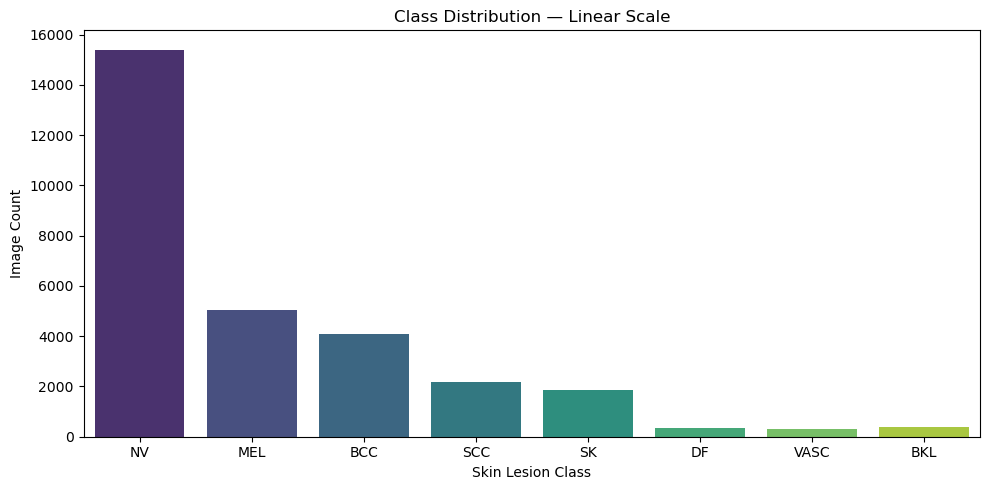

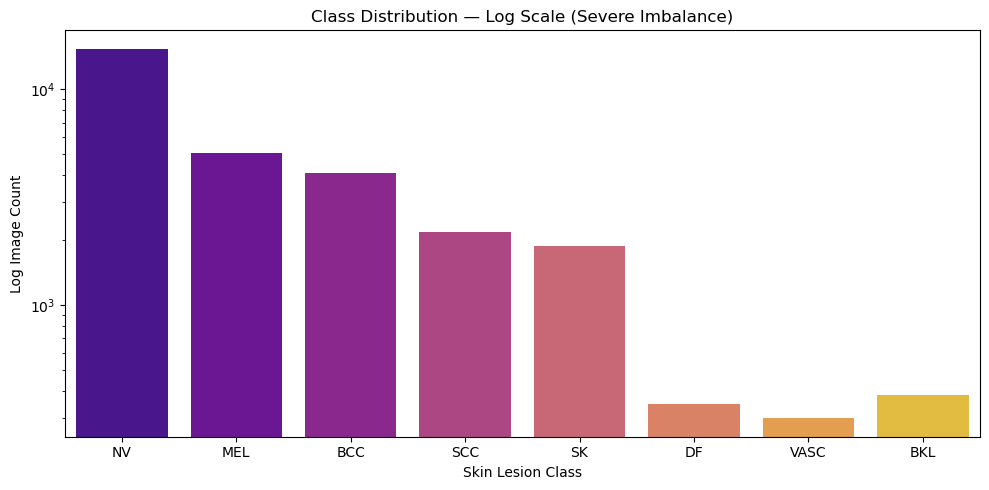

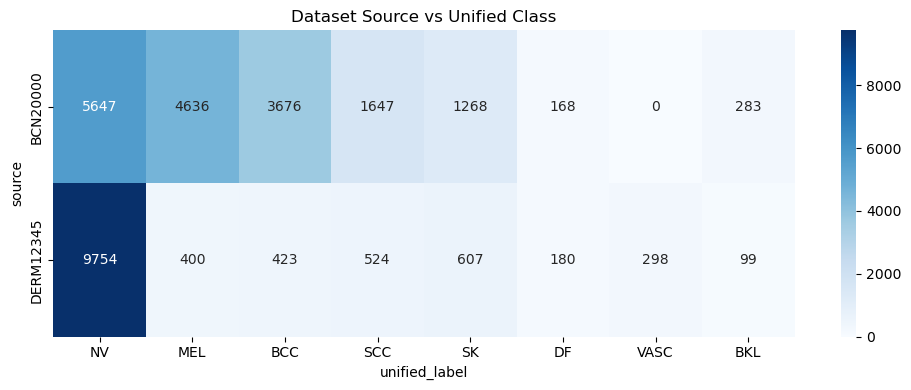

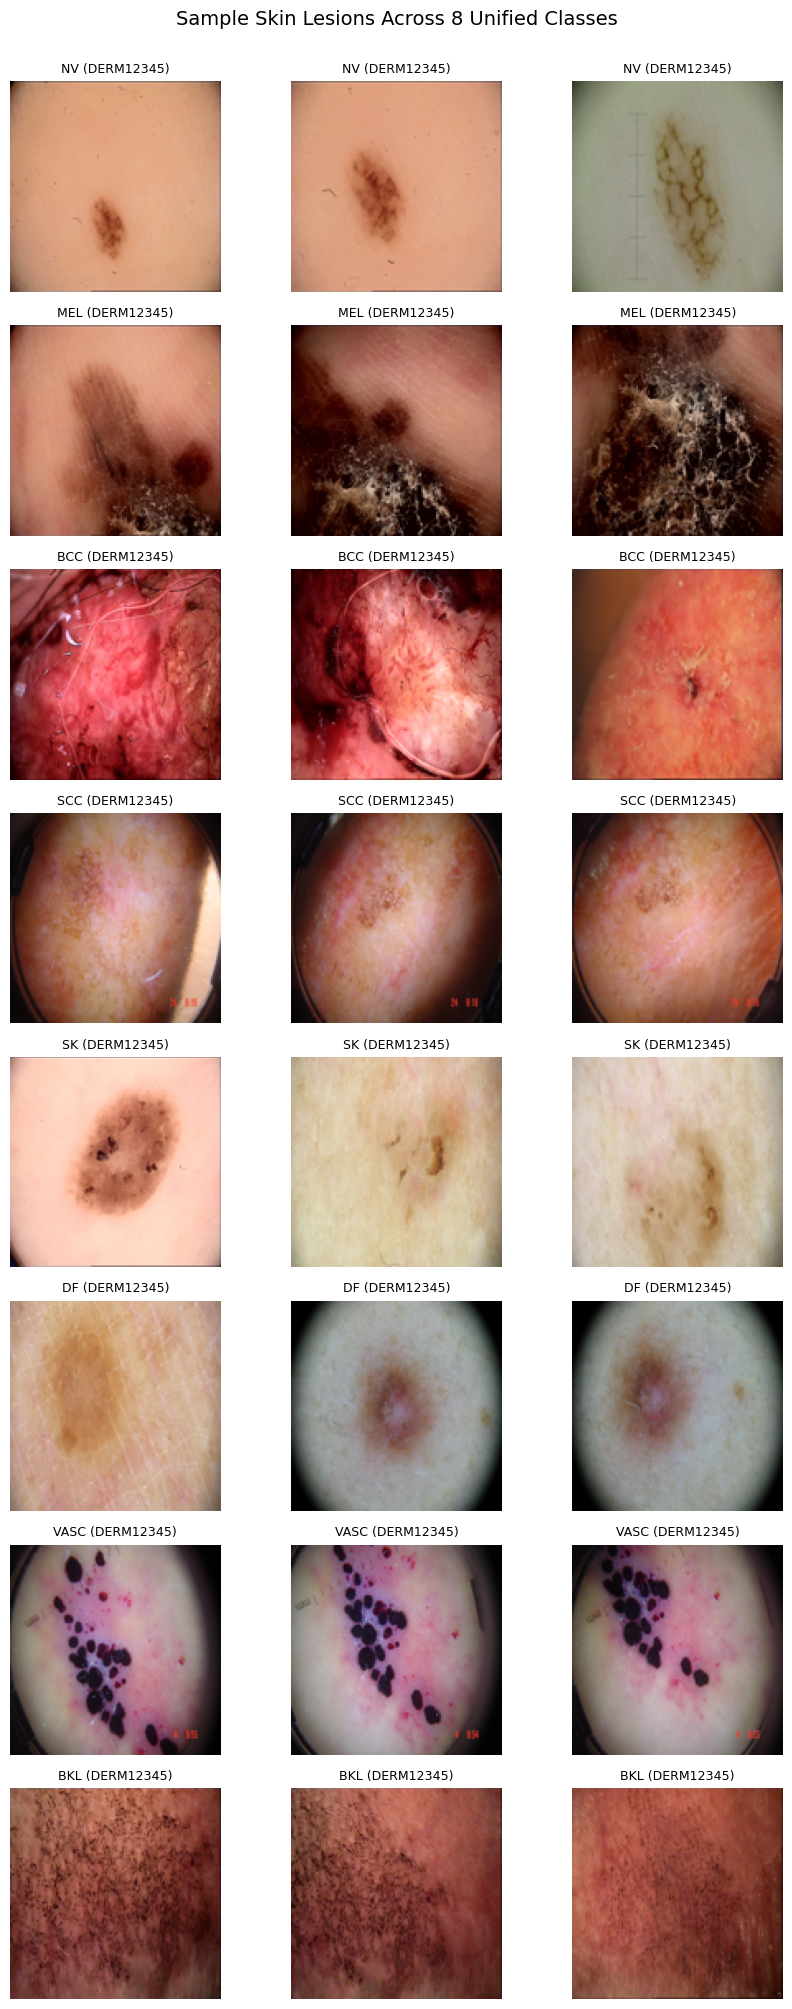

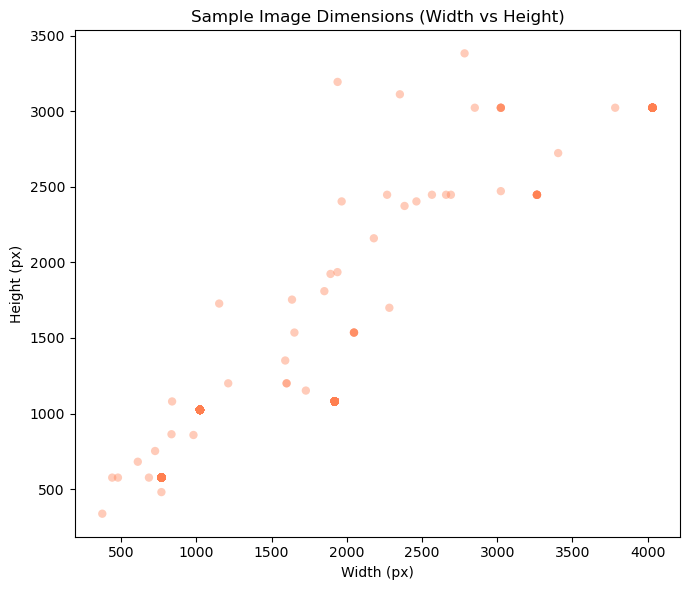

In [15]:
# 1. Class distribution (Linear Scale)
plt.figure(figsize=(10, 5))
sns.barplot(x=CLASS_NAMES, y=[class_counts[c] for c in CLASS_NAMES], palette="viridis")
plt.title("Class Distribution — Linear Scale")
plt.xlabel("Skin Lesion Class")
plt.ylabel("Image Count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_class_distribution.png", dpi=300)
plt.show()

# 2. Class distribution (Log Scale)
plt.figure(figsize=(10, 5))
sns.barplot(x=CLASS_NAMES, y=[class_counts[c] for c in CLASS_NAMES], palette="plasma")
plt.yscale("log")
plt.title("Class Distribution — Log Scale (Severe Imbalance)")
plt.xlabel("Skin Lesion Class")
plt.ylabel("Log Image Count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_class_log_scale.png", dpi=300)
plt.show()

# 3. Source x Class Crosstab Heatmap
plt.figure(figsize=(10, 4))
sns.heatmap(crosstab, annot=True, fmt="d", cmap="Blues")
plt.title("Dataset Source vs Unified Class")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_source_class.png", dpi=300)
plt.show()

# 4. Sample 3 images per class
fig, axes = plt.subplots(NUM_CLASSES, 3, figsize=(9, 20))
for r, cls in enumerate(CLASS_NAMES):
    cls_samples = all_data[all_data["unified_label"] == cls].head(3)
    for c, (_, row) in enumerate(cls_samples.iterrows()):
        ax = axes[r, c]
        try:
            with Image.open(row.image_path) as img:
                ax.imshow(img.resize((128, 128)))
        except Exception:
            ax.text(0.5, 0.5, "Image Error", ha="center")
        ax.set_title(f"{cls} ({row.source})", fontsize=9)
        ax.axis("off")
plt.suptitle("Sample Skin Lesions Across 8 Unified Classes", fontsize=14, y=1.002)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_sample_images.png", dpi=300)
plt.show()

# 5. Image dimension scatter (sample up to 1,000 images)
sampled_rows = all_data.sample(min(1000, len(all_data)), random_state=SEED)
dims = []
for p in sampled_rows["image_path"]:
    try:
        with Image.open(p) as img:
            dims.append(img.size) # (width, height)
    except Exception:
        pass
if dims:
    w, h = zip(*dims)
    plt.figure(figsize=(7, 6))
    plt.scatter(w, h, alpha=0.4, color="coral", edgecolors="none")
    plt.title("Sample Image Dimensions (Width vs Height)")
    plt.xlabel("Width (px)")
    plt.ylabel("Height (px)")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "eda_image_dimensions.png", dpi=300)
    plt.show()


# Section 15: Leakage-Safe Patient/Lesion Group Verification
Verify group_id definition (patient_id for DERM, lesion_id for BCN) to guarantee strict leakage-free partitioning.


In [16]:
# Issue 2 Fix: Verify group_id integrity cleanly without redundant reassignment
assert "group_id" in all_data.columns, "group_id column missing from all_data!"
assert all_data["group_id"].isna().sum() == 0, "Found missing values in group_id!"

print("Group Integrity Verification:")
print(f"Total dataset records:   {len(all_data)}")
print(f"Total unique groups:     {all_data['group_id'].nunique()}")
print(f"Unique groups from DERM: {all_data[all_data['source'] == 'DERM12345']['group_id'].nunique()}")
print(f"Unique groups from BCN:  {all_data[all_data['source'] == 'BCN20000']['group_id'].nunique()}")


Group Integrity Verification:
Total dataset records:   29610
Total unique groups:     6546
Unique groups from DERM: 1613
Unique groups from BCN:  4933


# Section 16: Two-Stage GroupShuffleSplit
Partition data into Train (70%), Validation (15%), and Test (15%) splits strictly respecting groups.


In [17]:
# Stage 1: train_val (85%) vs test (15%)
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
train_val_idx, test_idx = next(gss1.split(all_data, all_data["unified_label"], groups=all_data["group_id"]))

train_val_df = all_data.iloc[train_val_idx].copy().reset_index(drop=True)
test_df = all_data.iloc[test_idx].copy().reset_index(drop=True)

# Stage 2: train (82.35%) vs val (17.65%) of train_val (0.15 / 0.85 approx 0.17647)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=SEED)
train_idx, val_idx = next(gss2.split(train_val_df, train_val_df["unified_label"], groups=train_val_df["group_id"]))

train_df = train_val_df.iloc[train_idx].copy().reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].copy().reset_index(drop=True)

print(f"Train split size: {len(train_df):5d} ({len(train_df)/len(all_data):.1%})")
print(f"Val split size:   {len(val_df):5d} ({len(val_df)/len(all_data):.1%})")
print(f"Test split size:  {len(test_df):5d} ({len(test_df)/len(all_data):.1%})")


Train split size: 20356 (68.7%)
Val split size:    4822 (16.3%)
Test split size:   4432 (15.0%)


# Section 17: Mandatory Leakage Assertions & Split Persistence
Verify zero group leakage across splits and persist splits to CSV.


In [18]:
# Verify zero group leakage
A, B, C = set(train_df["group_id"]), set(val_df["group_id"]), set(test_df["group_id"])

assert len(A & B) == 0, "Train-Val group leak detected!"
assert len(A & C) == 0, "Train-Test group leak detected!"
assert len(B & C) == 0, "Val-Test group leak detected!"

print("Group leakage check PASSED: 0 overlap among Train, Val, and Test.")

# Save splits
train_df.to_csv(OUTPUT_DIR / "train_split.csv", index=False)
val_df.to_csv(OUTPUT_DIR / "val_split.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test_split.csv", index=False)
print("Saved train_split.csv, val_split.csv, and test_split.csv.")


Group leakage check PASSED: 0 overlap among Train, Val, and Test.
Saved train_split.csv, val_split.csv, and test_split.csv.


# Section 18: Classical Feature Extraction Functions
Implement feature extraction producing ~8,214 dimensions: HOG (8,100) + Color Histograms (96) + LBP (18).


In [19]:
IMG_SIZE = (128, 128)
HOG_ORIENTATIONS = 9
COLOR_BINS = 32
LBP_RADIUS = 2
LBP_POINTS = 16

def extract_classical_features(path):
    with Image.open(path) as im:
        img = np.asarray(im.convert("RGB").resize(IMG_SIZE), dtype=np.uint8)

    gray = rgb2gray(img)

    # 1. HOG features (~8,100 dims)
    h = hog(
        gray,
        orientations=HOG_ORIENTATIONS,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    ).astype(np.float32)

    # 2. Color Histograms per channel (96 dims)
    color = []
    for ch in range(3):
        hist, _ = np.histogram(img[:, :, ch], bins=COLOR_BINS, range=(0, 255), density=True)
        hist = hist.astype(np.float32)
        hist /= (hist.sum() + 1e-8)
        color.extend(hist)
    color = np.array(color, dtype=np.float32)

    # 3. LBP features (18 dims)
    lbp = local_binary_pattern(gray, LBP_POINTS, LBP_RADIUS, method="uniform")
    n_lbp_bins = LBP_POINTS + 2
    lbp_h, _ = np.histogram(lbp.ravel(), bins=np.arange(n_lbp_bins + 1), range=(0, n_lbp_bins), density=True)
    lbp_h = lbp_h.astype(np.float32)
    lbp_h /= (lbp_h.sum() + 1e-8)

    return np.concatenate([h, color, lbp_h]).astype(np.float32)

print("Feature extraction function configured successfully.")


Feature extraction function configured successfully.


Extracting features for Train set...
Train raw feature shape: (20356, 8214)
Extracting features for Val set...
Val raw feature shape:   (4822, 8214)
Extracting features for Test set...
Test raw feature shape:  (4432, 8214)
DataFrames successfully aligned and re-indexed.


Features after VarianceThreshold: 1307 (from 8214)
Features after PCA (95% variance): 448
Saved feature preprocessing transformers to output/ directory.


# Section 21: Classical ML Common Evaluation Wrapper
Implement a defensive evaluation wrapper that accepts explicit datasets and reports macro metrics.


In [22]:
def evaluate_ml_model(name, model, X_train, y_train, X_val, y_val, X_test, y_test, sample_weight=None):
    # BUG #8 FIX: Always pass explicit X_train and y_train
    start_time = time.time()
    if sample_weight is not None:
        model.fit(X_train, y_train, sample_weight=sample_weight)
    else:
        model.fit(X_train, y_train)
    elapsed_time = time.time() - start_time

    val_preds = model.predict(X_val)
    test_preds = model.predict(X_test)

    # Assert alignment
    assert len(val_preds) == len(y_val), f"Val preds length mismatch for {name}"
    assert len(test_preds) == len(y_test), f"Test preds length mismatch for {name}"

    metrics = {
        "Model": name,
        "Val Accuracy": accuracy_score(y_val, val_preds),
        "Val Precision": precision_score(y_val, val_preds, average="macro", zero_division=0),
        "Val Recall": recall_score(y_val, val_preds, average="macro", zero_division=0),
        "Val Macro-F1": f1_score(y_val, val_preds, average="macro", zero_division=0),
        "Test Accuracy": accuracy_score(y_test, test_preds),
        "Test Precision": precision_score(y_test, test_preds, average="macro", zero_division=0),
        "Test Recall": recall_score(y_test, test_preds, average="macro", zero_division=0),
        "Test Macro-F1": f1_score(y_test, test_preds, average="macro", zero_division=0),
        "Train Time (sec)": round(elapsed_time, 2)
    }

    print(f"=== {name} Evaluated in {elapsed_time:.1f}s ===")
    print(f"Val Macro-F1:  {metrics['Val Macro-F1']:.4f} | Test Macro-F1: {metrics['Test Macro-F1']:.4f}")
    return metrics, model, val_preds, test_preds

ml_results_list = []
test_predictions_dict = {
    "isic_id": test_df["isic_id"].values,
    "true_label": test_df["unified_label"].values
}


# Section 22: Classical ML — Random Forest
Train Random Forest with balanced subsample weighting.


In [23]:
rf_model = RandomForestClassifier(
    n_estimators=500,               # was 300
    max_features="sqrt",
    class_weight="balanced",        # ← CHANGED from "balanced_subsample"
    min_samples_leaf=2,             # ← NEW: prevent overfitting NV
    n_jobs=-1,
    random_state=SEED
)

rf_metrics, rf_model, rf_val_preds, rf_test_preds = evaluate_ml_model(
    "Random Forest", rf_model, X_train_pca, y_train, X_val_pca, y_val, X_test_pca, y_test
)
ml_results_list.append(rf_metrics)
test_predictions_dict["rf_pred"] = [IDX_TO_CLASS[p] for p in rf_test_preds]
joblib.dump(rf_model, OUTPUT_DIR / "random_forest.pkl")


=== Random Forest Evaluated in 109.1s ===
Val Macro-F1:  0.0890 | Test Macro-F1: 0.0878


['C:\\Users\\Saiyam Taneja\\Documents\\Personal Folder\\SkinCancerProject\\output\\random_forest.pkl']

# Section 23: Classical ML — Extra Trees
Train Extra Trees with balanced class weighting.


In [24]:
extra_model = ExtraTreesClassifier(
    n_estimators=300,
    max_features="sqrt",
    class_weight="balanced",
    n_jobs=-1,
    random_state=SEED
)

extra_metrics, extra_model, extra_val_preds, extra_test_preds = evaluate_ml_model(
    "Extra Trees", extra_model, X_train_pca, y_train, X_val_pca, y_val, X_test_pca, y_test
)
ml_results_list.append(extra_metrics)
test_predictions_dict["extra_pred"] = [IDX_TO_CLASS[p] for p in extra_test_preds]
joblib.dump(extra_model, OUTPUT_DIR / "extra_trees.pkl")


=== Extra Trees Evaluated in 15.1s ===
Val Macro-F1:  0.0873 | Test Macro-F1: 0.0856


['C:\\Users\\Saiyam Taneja\\Documents\\Personal Folder\\SkinCancerProject\\output\\extra_trees.pkl']

# Section 24: Classical ML — Logistic Regression
Train Logistic Regression with balanced weighting.


In [25]:
logreg_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=SEED
)

logreg_metrics, logreg_model, logreg_val_preds, logreg_test_preds = evaluate_ml_model(
    "Logistic Regression", logreg_model, X_train_pca, y_train, X_val_pca, y_val, X_test_pca, y_test
)
ml_results_list.append(logreg_metrics)
test_predictions_dict["logreg_pred"] = [IDX_TO_CLASS[p] for p in logreg_test_preds]
joblib.dump(logreg_model, OUTPUT_DIR / "logistic_regression.pkl")


=== Logistic Regression Evaluated in 49.4s ===
Val Macro-F1:  0.1959 | Test Macro-F1: 0.1825


['C:\\Users\\Saiyam Taneja\\Documents\\Personal Folder\\SkinCancerProject\\output\\logistic_regression.pkl']

# Section 25: Classical ML — HistGradientBoosting
Train HistGradientBoosting using balanced sample_weight directly via compute_sample_weight.


In [26]:
# Issue 3 Fix: Use clean and robust compute_sample_weight for balanced weighting
train_sample_weights = compute_sample_weight("balanced", y_train)

hgb_model = HistGradientBoostingClassifier(
    max_iter=250,
    learning_rate=0.08,
    max_leaf_nodes=31,
    random_state=SEED
)

hgb_metrics, hgb_model, hgb_val_preds, hgb_test_preds = evaluate_ml_model(
    "HistGradientBoosting", hgb_model, X_train_pca, y_train, X_val_pca, y_val, X_test_pca, y_test,
    sample_weight=train_sample_weights
)
ml_results_list.append(hgb_metrics)
test_predictions_dict["hgb_pred"] = [IDX_TO_CLASS[p] for p in hgb_test_preds]
joblib.dump(hgb_model, OUTPUT_DIR / "hist_gradient_boosting.pkl")


=== HistGradientBoosting Evaluated in 30.7s ===
Val Macro-F1:  0.2335 | Test Macro-F1: 0.2140


['C:\\Users\\Saiyam Taneja\\Documents\\Personal Folder\\SkinCancerProject\\output\\hist_gradient_boosting.pkl']

# Section 26: Classical ML Results & Confusion Matrices
Compile classical model metrics into a DataFrame and visualize Random Forest confusion matrix.


Classical ML Results:
                  Model  Val Macro-F1  Test Macro-F1  Test Accuracy  \
0         Random Forest      0.089023       0.087792       0.518953   
1           Extra Trees      0.087292       0.085580       0.517825   
2   Logistic Regression      0.195898       0.182541       0.313403   
3  HistGradientBoosting      0.233454       0.213973       0.463673   

   Train Time (sec)  
0            109.09  
1             15.11  
2             49.38  
3             30.74  

=== RANDOM FOREST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

          NV     0.5196    0.9983    0.6835      2296
         MEL     0.3810    0.0097    0.0189       827
         BCC     0.0000    0.0000    0.0000       617
         SCC     0.0000    0.0000    0.0000       303
          SK     0.0000    0.0000    0.0000       253
          DF     0.0000    0.0000    0.0000        61
        VASC     0.0000    0.0000    0.0000        34
         BKL     0.0000    0.0000 

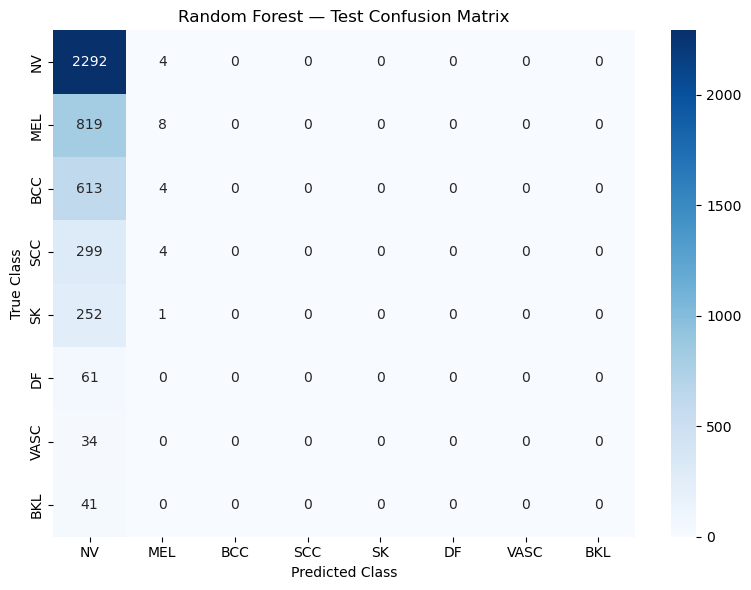

In [27]:
ml_results_df = pd.DataFrame(ml_results_list)
ml_results_df.to_csv(OUTPUT_DIR / "ml_results.csv", index=False)
print("Classical ML Results:")
print(ml_results_df[["Model", "Val Macro-F1", "Test Macro-F1", "Test Accuracy", "Train Time (sec)"]])

# Classification report for Random Forest
print("\n=== RANDOM FOREST CLASSIFICATION REPORT ===")
print(classification_report(y_test, rf_test_preds, target_names=CLASS_NAMES, digits=4, zero_division=0))

# Confusion Matrix for Random Forest
rf_cm = confusion_matrix(y_test, rf_test_preds, labels=np.arange(NUM_CLASSES))
plt.figure(figsize=(8, 6))
sns.heatmap(rf_cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Random Forest — Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rf_confusion_matrix.png", dpi=300)
plt.show()


In [28]:
print("=== RANDOM FOREST DIAGNOSTIC ===")
print("Classes seen by RF: ", rf_model.classes_)
print("Number of classes:  ", len(rf_model.classes_))
print("n_features_in_:     ", rf_model.n_features_in_)
print("class_weight param: ", rf_model.class_weight)

# Check class distribution in predictions
unique, counts = np.unique(rf_test_preds, return_counts=True)
print("\nPrediction distribution on test set:")
for u, c in zip(unique, counts):
    print(f"  Predicted {IDX_TO_CLASS[u]}: {c} ({c/len(rf_test_preds)*100:.2f}%)")

print("\nTrue distribution on test set:")
unique, counts = np.unique(y_test, return_counts=True)
for u, c in zip(unique, counts):
    print(f"  True {IDX_TO_CLASS[u]}: {c} ({c/len(y_test)*100:.2f}%)")

=== RANDOM FOREST DIAGNOSTIC ===
Classes seen by RF:  [0 1 2 3 4 5 6 7]
Number of classes:   8
n_features_in_:      448
class_weight param:  balanced

Prediction distribution on test set:
  Predicted NV: 4411 (99.53%)
  Predicted MEL: 21 (0.47%)

True distribution on test set:
  True NV: 2296 (51.81%)
  True MEL: 827 (18.66%)
  True BCC: 617 (13.92%)
  True SCC: 303 (6.84%)
  True SK: 253 (5.71%)
  True DF: 61 (1.38%)
  True VASC: 34 (0.77%)
  True BKL: 41 (0.93%)


In [29]:
print("=== ALIGNMENT SANITY CHECK ===")
# Pick 5 random training indices and verify feature matrix rows match DataFrame rows
import random
random.seed(42)
indices = random.sample(range(len(train_df)), 5)

for i in indices:
    df_label = train_df.iloc[i]["unified_label"]
    df_label_idx = CLASS_TO_IDX[df_label]
    y_label_idx = y_train[i]
    feature_mean = X_train_raw[i].mean()
    
    print(f"Row {i}: df_label={df_label} (idx {df_label_idx}), y_train[{i}]={y_label_idx}, feature_mean={feature_mean:.3f}")
    assert df_label_idx == y_label_idx, f"LABEL MISALIGNMENT AT ROW {i}!"

=== ALIGNMENT SANITY CHECK ===
Row 3648: df_label=NV (idx 0), y_train[3648]=0, feature_mean=0.145
Row 819: df_label=SCC (idx 3), y_train[819]=3, feature_mean=0.136
Row 9012: df_label=BCC (idx 2), y_train[9012]=2, feature_mean=0.148
Row 8024: df_label=NV (idx 0), y_train[8024]=0, feature_mean=0.139
Row 7314: df_label=NV (idx 0), y_train[7314]=0, feature_mean=0.150


In [30]:
print("=== FEATURE DISCRIMINABILITY TEST ===")
# Compute mean feature vector for each class in PCA space
class_means = {}
for cls_idx in range(NUM_CLASSES):
    mask = y_train == cls_idx
    if mask.sum() > 0:
        class_means[cls_idx] = X_train_pca[mask].mean(axis=0)
        print(f"{CLASS_NAMES[cls_idx]:5s}: {mask.sum():5d} samples, mean_norm={np.linalg.norm(class_means[cls_idx]):.3f}")

# Compute pairwise L2 distance between class means
print("\nPairwise class-mean distances (should be non-zero):")
for i in range(NUM_CLASSES):
    if i not in class_means: continue
    row = []
    for j in range(NUM_CLASSES):
        if j not in class_means: continue
        d = np.linalg.norm(class_means[i] - class_means[j])
        row.append(f"{d:.2f}")
    print(f"  {CLASS_NAMES[i]:5s}: " + " ".join(row))

=== FEATURE DISCRIMINABILITY TEST ===
NV   : 10518 samples, mean_norm=5.171
MEL  :  3490 samples, mean_norm=7.803
BCC  :  2861 samples, mean_norm=5.825
SCC  :  1528 samples, mean_norm=5.146
SK   :  1269 samples, mean_norm=2.976
DF   :   229 samples, mean_norm=3.562
VASC :   204 samples, mean_norm=9.703
BKL  :   257 samples, mean_norm=4.803

Pairwise class-mean distances (should be non-zero):
  NV   : 0.00 12.90 10.90 10.25 7.94 7.49 9.41 9.39
  MEL  : 12.90 0.00 3.60 3.44 5.62 7.20 14.85 5.24
  BCC  : 10.90 3.60 0.00 2.17 3.50 5.34 12.80 4.14
  SCC  : 10.25 3.44 2.17 0.00 3.01 4.87 12.00 3.50
  SK   : 7.94 5.62 3.50 3.01 0.00 3.49 10.50 3.46
  DF   : 7.49 7.20 5.34 4.87 3.49 0.00 9.78 4.48
  VASC : 9.41 14.85 12.80 12.00 10.50 9.78 0.00 11.82
  BKL  : 9.39 5.24 4.14 3.50 3.46 4.48 11.82 0.00


# Section 27: ANN Setup — Safe Class Weights & Architecture
Implement safe class weighting that handles potential missing classes and build the Multi-Layer Perceptron.


In [31]:
# BUG #9 FIX: Safe class weighting for ANN & CNN
def safe_class_weights(y, num_classes):
    present = np.unique(y)
    w = compute_class_weight("balanced", classes=present, y=y)
    full = np.ones(num_classes, dtype=np.float32)
    for cls, weight in zip(present, w):
        full[int(cls)] = weight
    return full

ann_weights = {i: float(w) for i, w in enumerate(safe_class_weights(y_train, NUM_CLASSES))}
print(f"Safe Class Weights for ANN: {ann_weights}")

# Architecture on same PCA feature space
pca_dim = X_train_pca.shape[1]

ann = keras.Sequential([
    layers.Input(shape=(pca_dim,)),
    layers.Dense(256),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.Dropout(0.35),
    layers.Dense(128),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.Dropout(0.30),
    layers.Dense(64),
    layers.ReLU(),
    layers.Dropout(0.25),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="ANN_SkinLesion")

ann.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
ann.summary()


Safe Class Weights for ANN: {0: 0.24191860854625702, 1: 0.7290831208229065, 2: 0.889374315738678, 3: 1.6652486324310303, 4: 2.005122184753418, 5: 11.111353874206543, 6: 12.473039627075195, 7: 9.900777816772461}


Model: "ANN_SkinLesion"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       114,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 158,152 (617.78 KB)

 Trainable params: 157,384 (614.78 KB)

 Non-trainable params: 768 (3.00 KB)

# Section 28: Training & Evaluating ANN Model
Train ANN with early stopping and reduce LR callbacks, record validation/test metrics, and export artifacts.


Epoch 1/30
319/319 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.2187 - loss: 2.1003 - val_accuracy: 0.4075 - val_loss: 1.8072 - learning_rate: 0.0010
Epoch 2/30
319/319 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.2799 - loss: 1.8856 - val_accuracy: 0.4063 - val_loss: 1.7238 - learning_rate: 0.0010
Epoch 3/30
319/319 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.2712 - loss: 1.7580 - val_accuracy: 0.3606 - val_loss: 1.6931 - learning_rate: 0.0010
Epoch 4/30
319/319 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.2851 - loss: 1.6531 - val_accuracy: 0.3667 - val_loss: 1.6703 - learning_rate: 0.0010
Epoch 5/30
319/319 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.3042 - loss: 1.5290 - val_accuracy: 0.3745 - val_loss: 1.6151 - learning_rate: 0.0010
Epoch 6/30
319/319 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.3194 - loss: 1.4180 - val_accuracy: 0.3795 - val_loss: 1.6043 - learning_rate: 0.0010
Epoch 7/30
319/319 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.3475 - loss: 1

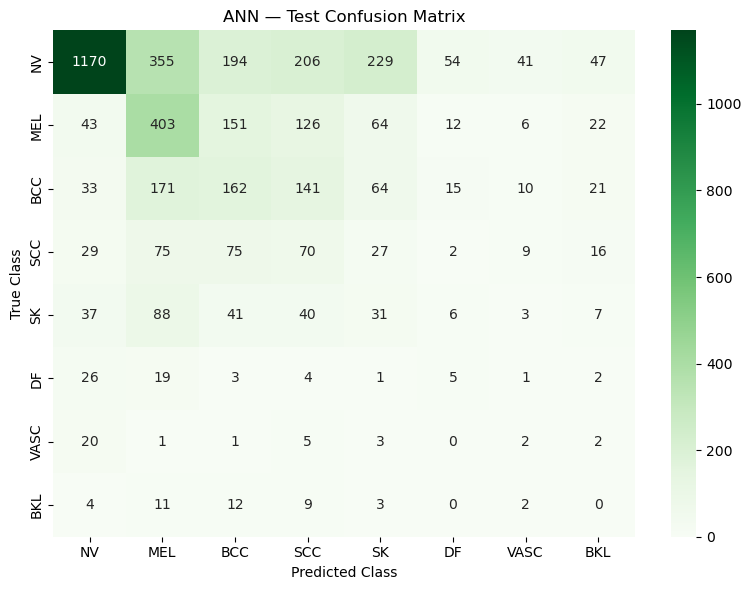

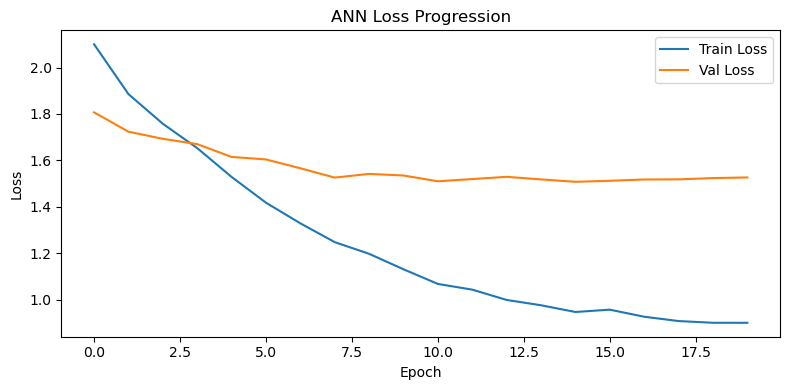

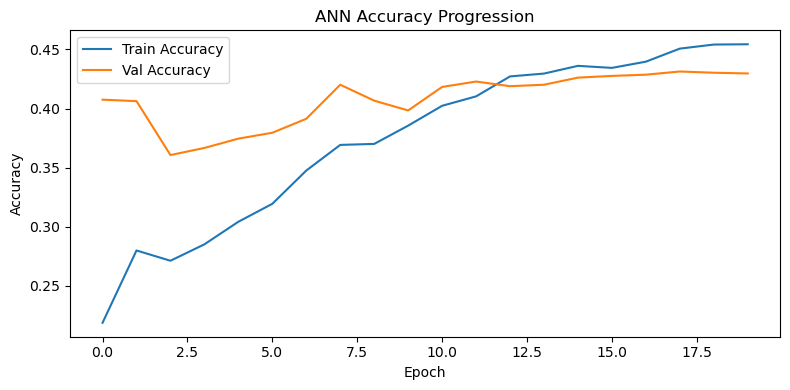

In [32]:
ann_callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ModelCheckpoint(str(OUTPUT_DIR / "best_ann.keras"), monitor="val_loss", save_best_only=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)
]

start_ann = time.time()
ann_history = ann.fit(
    X_train_pca, y_train,
    validation_data=(X_val_pca, y_val),
    epochs=30,
    batch_size=64,
    class_weight=ann_weights,
    callbacks=ann_callbacks,
    verbose=1
)
ann_train_time = round(time.time() - start_ann, 2)

ann.save(OUTPUT_DIR / "ann_final.keras")

# Evaluate ANN
ann_val_prob = ann.predict(X_val_pca)
ann_val_pred = np.argmax(ann_val_prob, axis=1)

ann_test_prob = ann.predict(X_test_pca)
ann_test_pred = np.argmax(ann_test_prob, axis=1)

test_predictions_dict["ann_pred"] = [IDX_TO_CLASS[p] for p in ann_test_pred]

ann_metrics = {
    "Model": "ANN",
    "Val Accuracy": accuracy_score(y_val, ann_val_pred),
    "Val Precision": precision_score(y_val, ann_val_pred, average="macro", zero_division=0),
    "Val Recall": recall_score(y_val, ann_val_pred, average="macro", zero_division=0),
    "Val Macro-F1": f1_score(y_val, ann_val_pred, average="macro", zero_division=0),
    "Test Accuracy": accuracy_score(y_test, ann_test_pred),
    "Test Precision": precision_score(y_test, ann_test_pred, average="macro", zero_division=0),
    "Test Recall": recall_score(y_test, ann_test_pred, average="macro", zero_division=0),
    "Test Macro-F1": f1_score(y_test, ann_test_pred, average="macro", zero_division=0),
    "Train Time (sec)": ann_train_time
}

# Confusion Matrix for ANN
ann_cm = confusion_matrix(y_test, ann_test_pred, labels=np.arange(NUM_CLASSES))
plt.figure(figsize=(8, 6))
sns.heatmap(ann_cm, annot=True, fmt="d", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("ANN — Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ann_confusion_matrix.png", dpi=300)
plt.show()

# ANN Learning Curves
plt.figure(figsize=(8, 4))
plt.plot(ann_history.history["loss"], label="Train Loss")
plt.plot(ann_history.history["val_loss"], label="Val Loss")
plt.title("ANN Loss Progression")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ann_loss.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(ann_history.history["accuracy"], label="Train Accuracy")
plt.plot(ann_history.history["val_accuracy"], label="Val Accuracy")
plt.title("ANN Accuracy Progression")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ann_accuracy.png", dpi=300)
plt.show()


# Section 29: CNN Setup — High-Performance tf.data Input Pipeline
Build a disk-cached, prefetched tf.data.Dataset pipeline with preprocessing directly inside load_image to prevent RAM OOM and model saving issues.


In [33]:
CNN_SIZE = (224, 224)
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

# Issue 5 Fix: Preprocess inside load_image directly to avoid Lambda serialization issues in Keras
def load_image(path, label):
    x = tf.io.read_file(path)
    x = tf.image.decode_image(x, channels=3, expand_animations=False)
    x.set_shape([None, None, 3])
    x = tf.image.resize(x, CNN_SIZE)
    x = tf.cast(x, tf.float32)  # Keep in [0, 255]
    x = keras.applications.efficientnet.preprocess_input(x)  # Direct EfficientNet preprocessing
    return x, label

# Issue 4 Fix: Use file-based cache to prevent OOM crash with 20k+ images (~17 GB RAM needed otherwise)
def make_ds(df, split_name="train", training=False):
    paths = df["image_path"].astype(str).values
    labels = df["unified_label"].map(CLASS_TO_IDX).values.astype(np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(min(len(df), 10000), seed=SEED, reshuffle_each_iteration=True)

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)

    # File-based cache path
    cache_file = OUTPUT_DIR / f"cache_{split_name}_{len(df)}.tf"
    ds = ds.cache(filename=str(cache_file))

    ds = ds.batch(BATCH)
    ds = ds.prefetch(AUTOTUNE)
    return ds

# BUG #7 & #10 FIX: Use the exact re-indexed DataFrames from Section 19
train_ds = make_ds(train_df, split_name="train", training=True)
val_ds   = make_ds(val_df, split_name="val", training=False)
test_ds  = make_ds(test_df, split_name="test", training=False)

print("tf.data file-cached input pipelines created successfully.")


tf.data file-cached input pipelines created successfully.


In [34]:
import os
cache_files = [f for f in os.listdir(OUTPUT_DIR) if f.startswith("cache_")]
print("Cache files present:", cache_files)

Cache files present: ['cache_test_4432.tf.data-00000-of-00001', 'cache_test_4432.tf.index', 'cache_train_20356.tf.data-00000-of-00001', 'cache_train_20356.tf.index', 'cache_val_4822.tf.data-00000-of-00001', 'cache_val_4822.tf.index']


In [35]:
import shutil
total, used, free = shutil.disk_usage(OUTPUT_DIR)
print(f"Drive: {OUTPUT_DIR.drive}")
print(f"Total: {total / 1e9:.2f} GB")
print(f"Used:  {used / 1e9:.2f} GB")
print(f"Free:  {free / 1e9:.2f} GB")

Drive: C:
Total: 491.05 GB
Used:  249.82 GB
Free:  241.23 GB


# Section 30: CNN Architecture (EfficientNetB0 Pretrained with Fallback)
Instantiate EfficientNetB0 backbone without Lambda layer for clean serialization, with narrowed exception handling.


In [36]:
cnn_weights = {i: float(w) for i, w in enumerate(safe_class_weights(
    train_df["unified_label"].map(CLASS_TO_IDX).values, NUM_CLASSES
))}

# Issue 6 Fix: Narrow exception to (OSError, ValueError) to catch network/weight errors without masking bugs
try:
    print("Attempting to load pretrained EfficientNetB0...")
    base = keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(*CNN_SIZE, 3)
    )
    base.trainable = False # Freeze backbone

    # Issue 5 Fix: Model without Lambda layer so cnn.save() serializes flawlessly
    cnn = keras.Sequential([
        layers.Input(shape=(*CNN_SIZE, 3)),
        keras.Sequential([
            layers.RandomFlip("horizontal_and_vertical"),
            layers.RandomRotation(0.08),
            layers.RandomZoom(0.10),
            layers.RandomContrast(0.10)
        ], name="augmentation"),
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ], name="EfficientNetB0_Classifier")
    cnn_backbone_name = "EfficientNetB0"
    print("Pretrained EfficientNetB0 initialized successfully.")
except (OSError, ValueError) as e:
    print(f"Pretrained weights unavailable ({type(e).__name__}: {e}). Falling back to custom CNN architecture from scratch...")
    cnn = keras.Sequential([
        layers.Input(shape=(*CNN_SIZE, 3)),
        keras.Sequential([
            layers.RandomFlip("horizontal_and_vertical"),
            layers.RandomRotation(0.08),
            layers.RandomZoom(0.10),
            layers.RandomContrast(0.10)
        ], name="augmentation"),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ], name="Custom_CNN_Scratch")
    cnn_backbone_name = "Custom_CNN_Scratch"

cnn.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
cnn.summary()


Attempting to load pretrained EfficientNetB0...
Pretrained EfficientNetB0 initialized successfully.


Model: "EfficientNetB0_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,571 (16.08 MB)

 Trainable params: 165,000 (644.53 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

# Section 31: Training & Comprehensive Evaluation of CNN
Train CNN, compute both Validation and Test metrics explicitly, and enforce alignment assertions.


In [37]:
import os
from pathlib import Path

# Delete all cache lock files
cache_dir = OUTPUT_DIR
lock_files = list(cache_dir.glob("cache_*.tf_*.lockfile"))
print(f"Found {len(lock_files)} lock files:")
for lf in lock_files:
    lf.unlink()
    print(f"  Deleted: {lf.name}")

# Optional: delete the entire cache to start fresh
# cache_files = list(cache_dir.glob("cache_*.tf*"))
# print(f"\nAlso removing {len(cache_files)} cache files (forces rebuild)")
# for cf in cache_files:
#     if cf.is_dir():
#         import shutil
#         shutil.rmtree(cf, ignore_errors=True)
#     else:
#         cf.unlink()
#     print(f"  Removed: {cf.name}")

print("\n✅ Lock files cleaned. Ready to retry Section 31.")

Found 0 lock files:

✅ Lock files cleaned. Ready to retry Section 31.


Epoch 1/20


637/637 ━━━━━━━━━━━━━━━━━━━━ 688s 1s/step - accuracy: 0.3581 - loss: 1.8741 - val_accuracy: 0.4548 - val_loss: 1.6151 - learning_rate: 1.0000e-04
Epoch 2/20
637/637 ━━━━━━━━━━━━━━━━━━━━ 575s 903ms/step - accuracy: 0.4587 - loss: 1.5905 - val_accuracy: 0.4903 - val_loss: 1.4319 - learning_rate: 1.0000e-04
Epoch 3/20
637/637 ━━━━━━━━━━━━━━━━━━━━ 665s 1s/step - accuracy: 0.4834 - loss: 1.4732 - val_accuracy: 0.5251 - val_loss: 1.3372 - learning_rate: 1.0000e-04
Epoch 4/20
637/637 ━━━━━━━━━━━━━━━━━━━━ 514s 807ms/step - accuracy: 0.4988 - loss: 1.4017 - val_accuracy: 0.5218 - val_loss: 1.3219 - learning_rate: 1.0000e-04
Epoch 5/20
637/637 ━━━━━━━━━━━━━━━━━━━━ 409s 642ms/step - accuracy: 0.5133 - loss: 1.3400 - val_accuracy: 0.5359 - val_loss: 1.2703 - learning_rate: 1.0000e-04
Epoch 6/20
637/637 ━━━━━━━━━━━━━━━━━━━━ 376s 590ms/step - accuracy: 0.5226 - loss: 1.2965 - val_accuracy: 0.5301 - val_loss: 1.2661 - learning_rate: 1.0000e-04
Epoch 7/20
637/637 ━━━━━━━━━━━━━━━━━━━━ 427s 670ms/step -

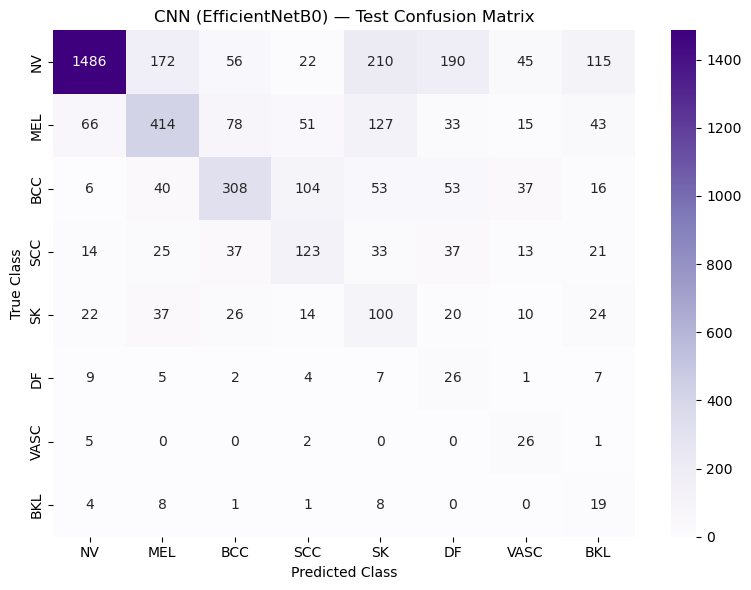

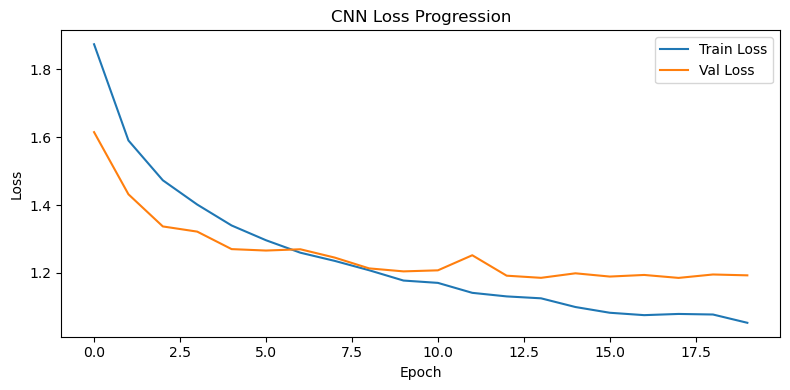

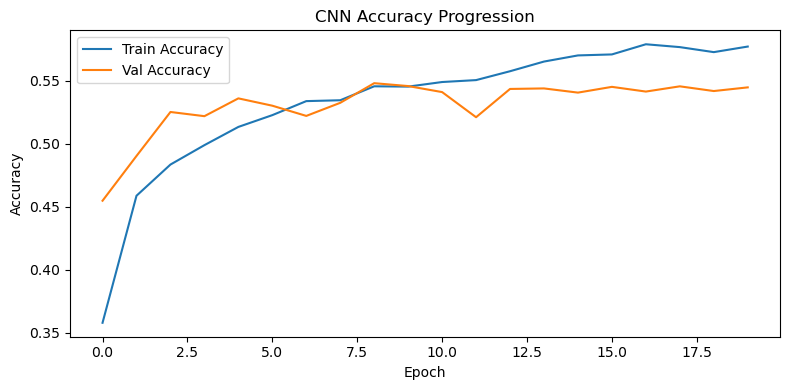

In [38]:
cnn_callbacks = [
    EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    ModelCheckpoint(str(OUTPUT_DIR / "best_cnn.keras"), monitor="val_loss", save_best_only=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)
]

start_cnn = time.time()
cnn_history = cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=cnn_weights,
    callbacks=cnn_callbacks,
    verbose=1
)
cnn_train_time = round(time.time() - start_cnn, 2)

# Flawless save now that Lambda layer is removed
cnn.save(OUTPUT_DIR / "cnn_final.keras")

# BUG #12 & #13 FIX: Compute both Val and Test metrics and verify alignment
print("Computing CNN Validation Predictions...")
cnn_val_prob = cnn.predict(val_ds)
cnn_val_pred = np.argmax(cnn_val_prob, axis=1)
cnn_val_true = val_df["unified_label"].map(CLASS_TO_IDX).values
assert len(cnn_val_pred) == len(cnn_val_true), "CNN Val prediction count mismatch!"

print("Computing CNN Test Predictions...")
cnn_test_prob = cnn.predict(test_ds)
cnn_test_pred = np.argmax(cnn_test_prob, axis=1)
cnn_y_true    = test_df["unified_label"].map(CLASS_TO_IDX).values
assert len(cnn_test_pred) == len(cnn_y_true), "CNN Test prediction count mismatch!"

test_predictions_dict["cnn_pred"] = [IDX_TO_CLASS[p] for p in cnn_test_pred]

cnn_metrics = {
    "Model": f"CNN ({cnn_backbone_name})",
    "Val Accuracy": accuracy_score(cnn_val_true, cnn_val_pred),
    "Val Precision": precision_score(cnn_val_true, cnn_val_pred, average="macro", zero_division=0),
    "Val Recall": recall_score(cnn_val_true, cnn_val_pred, average="macro", zero_division=0),
    "Val Macro-F1": f1_score(cnn_val_true, cnn_val_pred, average="macro", zero_division=0),
    "Test Accuracy": accuracy_score(cnn_y_true, cnn_test_pred),
    "Test Precision": precision_score(cnn_y_true, cnn_test_pred, average="macro", zero_division=0),
    "Test Recall": recall_score(cnn_y_true, cnn_test_pred, average="macro", zero_division=0),
    "Test Macro-F1": f1_score(cnn_y_true, cnn_test_pred, average="macro", zero_division=0),
    "Train Time (sec)": cnn_train_time
}

# Confusion Matrix for CNN
cnn_cm = confusion_matrix(cnn_y_true, cnn_test_pred, labels=np.arange(NUM_CLASSES))
plt.figure(figsize=(8, 6))
sns.heatmap(cnn_cm, annot=True, fmt="d", cmap="Purples", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f"CNN ({cnn_backbone_name}) — Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cnn_confusion_matrix.png", dpi=300)
plt.show()

# CNN Learning Curves
plt.figure(figsize=(8, 4))
plt.plot(cnn_history.history["loss"], label="Train Loss")
plt.plot(cnn_history.history["val_loss"], label="Val Loss")
plt.title("CNN Loss Progression")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cnn_loss.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(cnn_history.history["accuracy"], label="Train Accuracy")
plt.plot(cnn_history.history["val_accuracy"], label="Val Accuracy")
plt.title("CNN Accuracy Progression")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cnn_accuracy.png", dpi=300)
plt.show()


Starting ResNet50 training...
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 8s 0us/step
Epoch 1/15
637/637 ━━━━━━━━━━━━━━━━━━━━ 1232s 2s/step - accuracy: 0.3998 - loss: 1.8375 - val_accuracy: 0.5017 - val_loss: 1.3667 - learning_rate: 0.0010
Epoch 2/15
637/637 ━━━━━━━━━━━━━━━━━━━━ 993s 2s/step - accuracy: 0.4872 - loss: 1.4145 - val_accuracy: 0.5274 - val_loss: 1.2967 - learning_rate: 0.0010
Epoch 3/15
637/637 ━━━━━━━━━━━━━━━━━━━━ 913s 1s/step - accuracy: 0.5189 - loss: 1.2659 - val_accuracy: 0.5232 - val_loss: 1.2979 - learning_rate: 0.0010
Epoch 4/15
637/637 ━━━━━━━━━━━━━━━━━━━━ 916s 1s/step - accuracy: 0.5256 - loss: 1.2329 - val_accuracy: 0.5545 - val_loss: 1.2258 - learning_rate: 0.0010
Epoch 5/15
637/637 ━━━━━━━━━━━━━━━━━━━━ 915s 1s/step - accuracy: 0.5465 - loss: 1.1563 - val_accuracy: 0.5238 - val_loss: 1.3532 - learning_rate: 0.0010
Epoch 6/15
637/637 ━━━━━━━━━━━━━━━━━━━━ 867s 1s/step - accuracy: 0.5545 - loss: 1.1301 - val_accuracy: 0.5274 - val_loss: 1.3370 - learning_rate: 0.0010


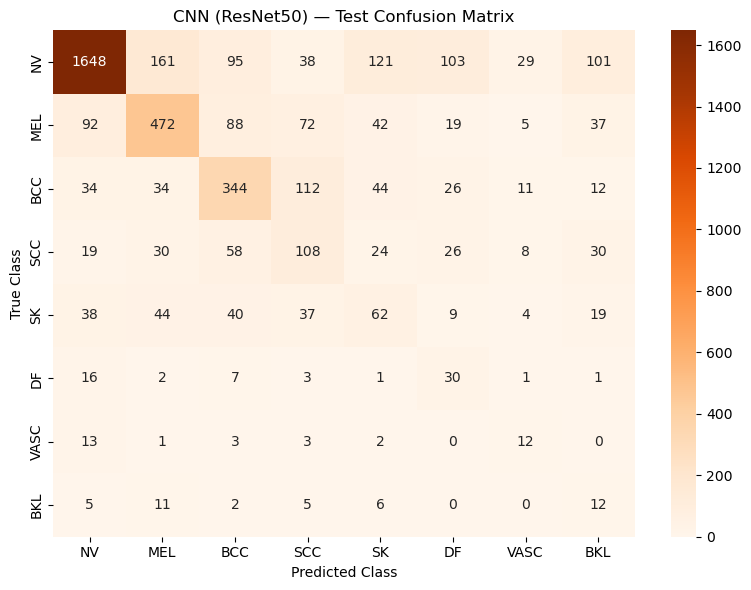

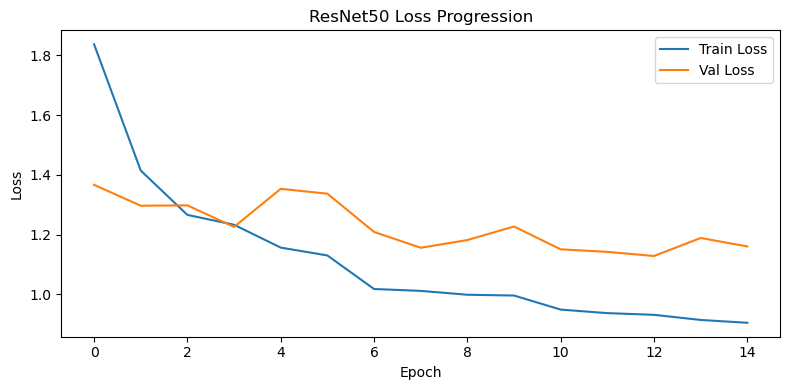

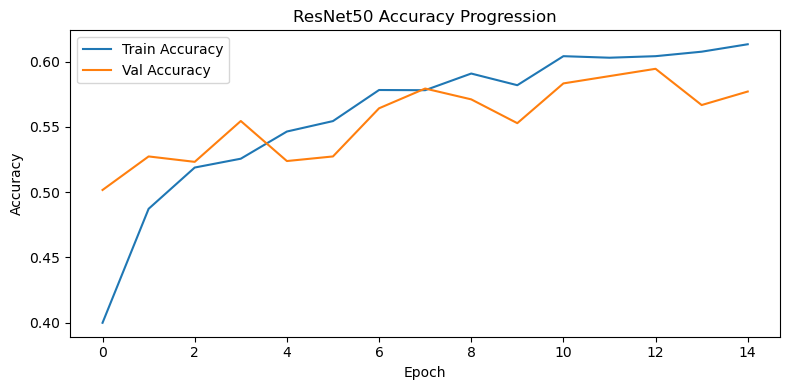

NameError: name 'full_eval' is not defined

In [41]:
# ==========================================
# ResNet50 Training & Evaluation
# ==========================================

# 1. Define Callbacks
resnet_callbacks = [
    EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    ModelCheckpoint(str(OUTPUT_DIR / "best_resnet.keras"), monitor="val_loss", save_best_only=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)
]

# 2. Train the model
print("Starting ResNet50 training...")
start_resnet = time.time()
# Build ResNet50 before training
resnet_base = keras.applications.ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
resnet_base.trainable = False

resnet_inputs = keras.Input(shape=(224, 224, 3))
x = resnet_base(resnet_inputs, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.3)(x)
resnet_outputs = keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)

resnet_model = keras.Model(resnet_inputs, resnet_outputs)

resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_history = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=cnn_weights,
    callbacks=resnet_callbacks,
    verbose=1
)
resnet_train_time = round(time.time() - start_resnet, 2)

# 3. Save the model
resnet_model.save(OUTPUT_DIR / "resnet_final.keras")

# 4. Compute Validation Predictions
print("Computing ResNet50 Validation Predictions...")
resnet_val_prob = resnet_model.predict(val_ds)
resnet_val_pred = np.argmax(resnet_val_prob, axis=1)
resnet_val_true = val_df["unified_label"].map(CLASS_TO_IDX).values
assert len(resnet_val_pred) == len(resnet_val_true), "ResNet Val prediction count mismatch!"

# 5. Compute Test Predictions
print("Computing ResNet50 Test Predictions...")
resnet_test_prob = resnet_model.predict(test_ds)
resnet_test_pred = np.argmax(resnet_test_prob, axis=1)
resnet_y_true    = test_df["unified_label"].map(CLASS_TO_IDX).values
assert len(resnet_test_pred) == len(resnet_y_true), "ResNet Test prediction count mismatch!"

test_predictions_dict["resnet_pred"] = [IDX_TO_CLASS[p] for p in resnet_test_pred]

# 6. Calculate Metrics
resnet_metrics = {
    "Model": "CNN (ResNet50)",
    "Val Accuracy": accuracy_score(resnet_val_true, resnet_val_pred),
    "Val Precision": precision_score(resnet_val_true, resnet_val_pred, average="macro", zero_division=0),
    "Val Recall": recall_score(resnet_val_true, resnet_val_pred, average="macro", zero_division=0),
    "Val Macro-F1": f1_score(resnet_val_true, resnet_val_pred, average="macro", zero_division=0),
    "Test Accuracy": accuracy_score(resnet_y_true, resnet_test_pred),
    "Test Precision": precision_score(resnet_y_true, resnet_test_pred, average="macro", zero_division=0),
    "Test Recall": recall_score(resnet_y_true, resnet_test_pred, average="macro", zero_division=0),
    "Test Macro-F1": f1_score(resnet_y_true, resnet_test_pred, average="macro", zero_division=0),
    "Train Time (sec)": resnet_train_time
}

# 7. Plot Confusion Matrix
resnet_cm = confusion_matrix(resnet_y_true, resnet_test_pred, labels=np.arange(NUM_CLASSES))
plt.figure(figsize=(8, 6))
sns.heatmap(resnet_cm, annot=True, fmt="d", cmap="Oranges", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("CNN (ResNet50) — Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "resnet_confusion_matrix.png", dpi=300)
plt.show()

# 8. Plot Learning Curves (Loss)
plt.figure(figsize=(8, 4))
plt.plot(resnet_history.history["loss"], label="Train Loss")
plt.plot(resnet_history.history["val_loss"], label="Val Loss")
plt.title("ResNet50 Loss Progression")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "resnet_loss.png", dpi=300)
plt.show()

# 9. Plot Learning Curves (Accuracy)
plt.figure(figsize=(8, 4))
plt.plot(resnet_history.history["accuracy"], label="Train Accuracy")
plt.plot(resnet_history.history["val_accuracy"], label="Val Accuracy")
plt.title("ResNet50 Accuracy Progression")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "resnet_accuracy.png", dpi=300)
plt.show()

# 10. Append to overall results list for the final comparison table
ml_results_list.append(resnet_metrics) 

# Section 32: Final Model Comparison, Visualizations & Summary JSON
Collate all models into the final comparison table, save predictions, plot comparative Test Macro-F1, and export project summary JSON.


=== FINAL MODEL COMPARISON TABLE (SORTED BY MACRO-F1) ===
               Model  Val Accuracy  Val Precision  Val Recall  Val Macro-F1  Test Accuracy  Test Precision  Test Recall  Test Macro-F1  Train Time (sec)
CNN (EfficientNetB0)      0.545417       0.375478    0.518818      0.385515       0.564531        0.376788     0.512819       0.380064          10826.36
      CNN (ResNet50)      0.594567       0.375432    0.481177      0.392858       0.606498        0.363592     0.448121       0.377836          13915.07
HistGradientBoosting      0.488594       0.230477    0.250179      0.233454       0.463673        0.218332     0.221189       0.213973             30.74
                 ANN      0.426172       0.242588    0.262481      0.241097       0.415839        0.217695     0.219224       0.207408             93.38
 Logistic Regression      0.332642       0.219696    0.246481      0.195898       0.313403        0.213743     0.227586       0.182541             49.38
       Random Forest    

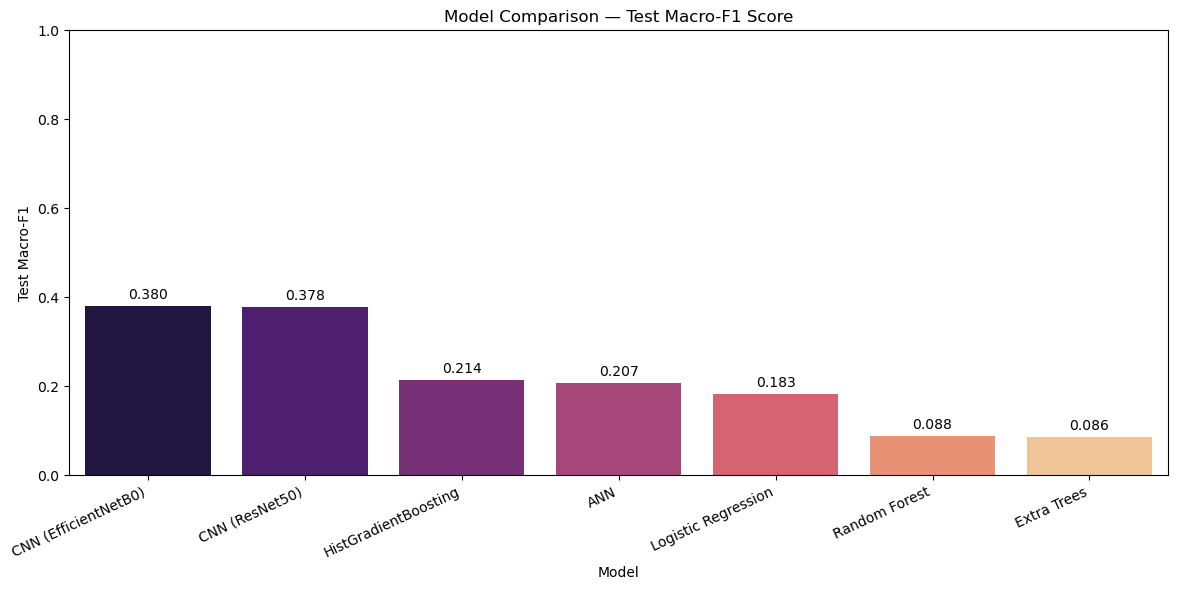


=== PROJECT SUMMARY JSON ===
{
  "seed": 42,
  "classes": [
    "NV",
    "MEL",
    "BCC",
    "SCC",
    "SK",
    "DF",
    "VASC",
    "BKL"
  ],
  "total_images": 29610,
  "train_images": 20356,
  "validation_images": 4822,
  "test_images": 4432,
  "classical_features_before_pca": 8214,
  "classical_features_after_pca": 448,
  "pca_explained_variance": 0.9500312805175781,
  "best_model": "CNN (EfficientNetB0)",
  "best_macro_f1": 0.38006418309296985,
  "cnn_backbone_efficientnet": "EfficientNetB0",
  "cnn_backbone_resnet": "ResNet50"
}

Pipeline execution complete. All artifacts successfully generated in output/ directory.


In [44]:
# 1. Collate all model results (Adding ResNet50 explicitly)
# Note: resnet_metrics is defined in the ResNet50 cell
all_results = ml_results_list + [ann_metrics, cnn_metrics, resnet_metrics]
final_comparison_df = pd.DataFrame(all_results)

# Sort by Test Macro-F1 so the best model is on top
final_comparison_df = final_comparison_df.sort_values(by="Test Macro-F1", ascending=False)

columns_order = [
    "Model",
    "Val Accuracy", "Val Precision", "Val Recall", "Val Macro-F1",
    "Test Accuracy", "Test Precision", "Test Recall", "Test Macro-F1",
    "Train Time (sec)"
]
final_comparison_df = final_comparison_df[columns_order]

# Save comparison table
final_comparison_df.to_csv(OUTPUT_DIR / "final_model_comparison.csv", index=False)
print("=== FINAL MODEL COMPARISON TABLE (SORTED BY MACRO-F1) ===")
print(final_comparison_df.to_string(index=False))

# 2. Save test predictions across all models
pred_df = pd.DataFrame(test_predictions_dict)
pred_df.to_csv(OUTPUT_DIR / "test_predictions_all_models.csv", index=False)
print(f"\nSaved test predictions to {OUTPUT_DIR / 'test_predictions_all_models.csv'}")

# 3. Model comparison bar chart (Test Macro-F1)
plt.figure(figsize=(12, 6))
bar_plot = sns.barplot(
    data=final_comparison_df,
    x="Model",
    y="Test Macro-F1",
    palette="magma"
)
plt.title("Model Comparison — Test Macro-F1 Score")
plt.xlabel("Model")
plt.ylabel("Test Macro-F1")
plt.ylim(0, 1.0)

# Adding text labels on top of bars
for p in bar_plot.patches:
    bar_plot.annotate(f"{p.get_height():.3f}",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha="center", va="bottom", fontsize=10, xytext=(0, 3),
                     textcoords="offset points")

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_comparison.png", dpi=300)
plt.show()

# 4. Project Summary JSON
summary_dict = {
    "seed": SEED,
    "classes": CLASS_NAMES,
    "total_images": int(len(all_data)),
    "train_images": int(len(train_df)),
    "validation_images": int(len(val_df)),
    "test_images": int(len(test_df)),
    "classical_features_before_pca": int(X_train_raw.shape[1]),
    "classical_features_after_pca": int(X_train_pca.shape[1]),
    "pca_explained_variance": float(np.sum(pca.explained_variance_ratio_)),
    "best_model": final_comparison_df.iloc[0]["Model"],
    "best_macro_f1": float(final_comparison_df.iloc[0]["Test Macro-F1"]),
    "cnn_backbone_efficientnet": cnn_backbone_name,
    "cnn_backbone_resnet": "ResNet50"
}

with open(OUTPUT_DIR / "project_summary.json", "w") as f:
    json.dump(summary_dict, f, indent=2)

print("\n=== PROJECT SUMMARY JSON ===")
print(json.dumps(summary_dict, indent=2))
print("\nPipeline execution complete. All artifacts successfully generated in output/ directory.")

Generating Grad-CAM Explanations...

True: NV | Predicted: NV (80.16% confidence)


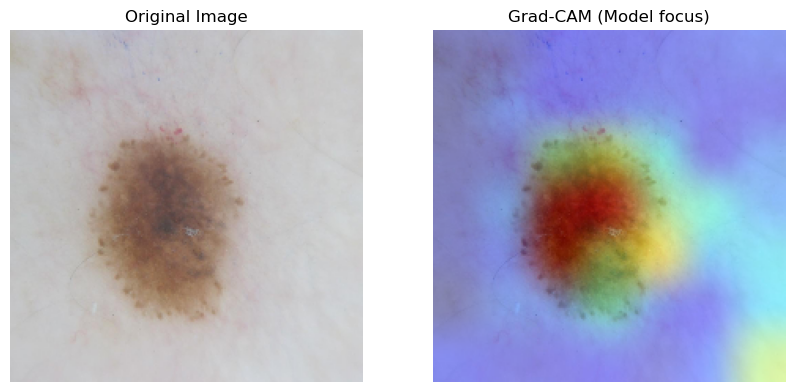


True: NV | Predicted: NV (94.04% confidence)


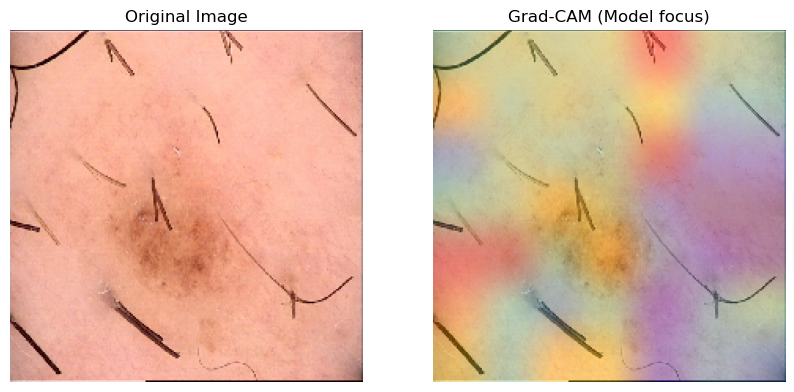


True: BCC | Predicted: BCC (45.33% confidence)


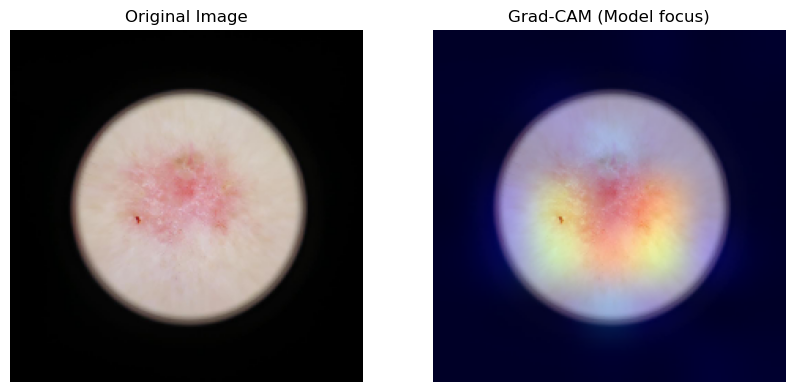

In [43]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from tensorflow.keras.preprocessing import image
import random

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # 1. Create a model that maps the input image to the activations of the last conv layer
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )

    # 2. Compute the gradient of the top predicted class for our input image with respect to the activations
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # 3. This is the gradient of the output neuron with regard to the output feature map
    grads = tape.gradient(class_channel, last_conv_layer_output)

    # 4. This is a vector where each entry is the mean intensity of the gradient over a specific feature map channel
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # 5. We multiply each channel in the feature map array by "how important this channel is"
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # 6. For visualization purpose, we will also normalize the heatmap between 0 & 1
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def display_gradcam(img_path, heatmap, alpha=0.4):
    # Load the original image
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
    img = tf.keras.preprocessing.image.img_to_array(img)

    # Rescale heatmap to a range 0-255
    heatmap = np.uint8(255 * heatmap)

    # Use jet colormap to colorize heatmap
    jet = cm.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]

    # Create an image with RGB colorized heatmap
    jet_heatmap = tf.keras.preprocessing.image.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = tf.keras.preprocessing.image.img_to_array(jet_heatmap)

    # Superimpose the heatmap on original image
    superimposed_img = jet_heatmap * alpha + img
    superimposed_img = tf.keras.preprocessing.image.array_to_img(superimposed_img)

    # Display
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(img.astype('uint8'))
    axes[0].set_title("Original Image")
    axes[0].axis('off')
    
    axes[1].imshow(superimposed_img)
    axes[1].set_title("Grad-CAM (Model focus)")
    axes[1].axis('off')
    plt.show()

# --- RUN EXPLANATION ON 3 RANDOM TEST IMAGES ---
print("Generating Grad-CAM Explanations...")

# ResNet50 ki last convolution layer ka naam 'conv5_block3_out' hota hai
# (Agar EfficientNet use kar rahe ho, toh iska naam 'top_activation' hota hai)
target_layer = "conv5_block3_out" 

# Pick 3 random images from test set
sample_df = test_df.sample(3, random_state=SEED)

for idx, row in sample_df.iterrows():
    img_path = row['image_path']
    true_label = row['unified_label']
    
    # Prepare image
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    
    # Predict
    preds = resnet_model.predict(img_array, verbose=0)
    pred_class_idx = np.argmax(preds[0])
    pred_label = IDX_TO_CLASS[pred_class_idx]
    confidence = preds[0][pred_class_idx] * 100
    
    print(f"\nTrue: {true_label} | Predicted: {pred_label} ({confidence:.2f}% confidence)")
    
    # Generate Heatmap and display
    def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
        # The CNN backbone is nested inside the classification model.
        backbone = model.get_layer("resnet50")
        target_layer = backbone.get_layer(last_conv_layer_name)

        # Model returning convolutional activations and backbone output.
        feature_model = tf.keras.Model(
            inputs=backbone.input,
            outputs=[target_layer.output, backbone.output]
        )

        backbone_index = model.layers.index(backbone)
        head_layers = model.layers[backbone_index + 1:]

        with tf.GradientTape() as tape:
            conv_outputs, backbone_output = feature_model(img_array)
            tape.watch(conv_outputs)

            predictions = backbone_output
            for layer in head_layers:
                predictions = layer(predictions, training=False)

            if pred_index is None:
                pred_index = tf.argmax(predictions[0])

            class_channel = predictions[:, pred_index]

        grads = tape.gradient(class_channel, conv_outputs)
        pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

        conv_outputs = conv_outputs[0]
        heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)
        heatmap = tf.maximum(heatmap, 0)

        max_value = tf.reduce_max(heatmap)
        heatmap = tf.where(
            max_value > 0,
            heatmap / max_value,
            tf.zeros_like(heatmap)
        )

        return heatmap.numpy()


    # ResNet50's final convolutional layer is inside the nested backbone.
    target_layer = "conv5_block3_out"

    heatmap = make_gradcam_heatmap(
        img_array,
        resnet_model,
        target_layer,
        int(pred_class_idx)
    )
    display_gradcam(img_path, heatmap)

In [46]:
# SECTION 30c: Vision Transformer (ViT) Architecture
print("Building Vision Transformer (ViT) model...")
try:
    base_vit = keras.applications.ViTB16(
        include_top=False,
        weights="imagenet",
        input_shape=(*CNN_SIZE, 3) # 224x224
    )
    base_vit.trainable = False # Freeze backbone

    vit_model = keras.Sequential([
        layers.Input(shape=(*CNN_SIZE, 3)),
        keras.Sequential([
            layers.RandomFlip("horizontal_and_vertical"),
            layers.RandomRotation(0.08),
            layers.RandomZoom(0.10),
            layers.RandomContrast(0.10)
        ], name="augmentation_vit"),
        base_vit,
        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ], name="ViT_Classifier")
    
    vit_backbone_name = "VisionTransformer"
    print("ViT initialized successfully.")
except Exception as e:
    print(f"ViT failed to load: {e}")

# Build a lightweight Vision Transformer fallback when ViTB16 is unavailable
if "vit_model" not in globals():
    print("ViTB16 is unavailable; building a Vision Transformer from scratch.")

    inputs = keras.Input(shape=(*CNN_SIZE, 3))

    x = layers.Conv2D(
        128, kernel_size=16, strides=16, padding="valid"
    )(inputs)

    x = layers.Reshape((-1, 128))(x)

    for _ in range(4):
        attention_input = layers.LayerNormalization()(x)
        attention_output = layers.MultiHeadAttention(
            num_heads=4,
            key_dim=32,
            dropout=0.1
        )(attention_input, attention_input)
        x = layers.Add()([x, attention_output])

        mlp_input = layers.LayerNormalization()(x)
        mlp_output = layers.Dense(256, activation="gelu")(mlp_input)
        mlp_output = layers.Dropout(0.1)(mlp_output)
        mlp_output = layers.Dense(128)(mlp_output)
        x = layers.Add()([x, mlp_output])

    x = layers.LayerNormalization()(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    vit_model = keras.Model(inputs, outputs, name="VisionTransformer_Classifier")
    vit_backbone_name = "VisionTransformer_Scratch"

vit_model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

vit_model.summary()
vit_model.summary()

Building Vision Transformer (ViT) model...
ViT failed to load: module 'keras.applications' has no attribute 'ViTB16'
ViTB16 is unavailable; building a Vision Transformer from scratch.


Model: "VisionTransformer_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 14, 14,    │     98,432 │ input_layer_6[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 196, 128)  │          0 │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 196, 128)  │        256 │ reshape[0][0]     │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 128)  │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 196, 128)  │          0 │ reshape[0][0],    │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 128)  │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 196, 256)  │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 196, 256)  │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 196, 128)  │     32,896 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 196, 128)  │          0 │ add[0][0],        │
│                     │                   │            │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 128)  │        256 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 128)  │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 196, 128)  │          0 │ add_1[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 128)  │        256 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 196, 256)  │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 196, 256)  │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 196, 128)  │     32,896 │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 196, 128)  │          0 │ add_2[0][0],      │
│                     │                   │            │ dense_10[0][0]  

 Total params: 663,688 (2.53 MB)

 Trainable params: 663,688 (2.53 MB)

 Non-trainable params: 0 (0.00 B)

Model: "VisionTransformer_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 14, 14,    │     98,432 │ input_layer_6[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 196, 128)  │          0 │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 196, 128)  │        256 │ reshape[0][0]     │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 128)  │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 196, 128)  │          0 │ reshape[0][0],    │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 128)  │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 196, 256)  │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 196, 256)  │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 196, 128)  │     32,896 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 196, 128)  │          0 │ add[0][0],        │
│                     │                   │            │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 128)  │        256 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 128)  │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 196, 128)  │          0 │ add_1[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 128)  │        256 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 196, 256)  │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 196, 256)  │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 196, 128)  │     32,896 │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 196, 128)  │          0 │ add_2[0][0],      │
│                     │                   │            │ dense_10[0][0]  

 Total params: 663,688 (2.53 MB)

 Trainable params: 663,688 (2.53 MB)

 Non-trainable params: 0 (0.00 B)

Starting Vision Transformer (ViT) training... (This will take a while)
Epoch 1/10


637/637 ━━━━━━━━━━━━━━━━━━━━ 296s 465ms/step - accuracy: 0.1651 - loss: 2.0538 - val_accuracy: 0.2399 - val_loss: 2.0313 - learning_rate: 2.5000e-05
Epoch 2/10
637/637 ━━━━━━━━━━━━━━━━━━━━ 330s 519ms/step - accuracy: 0.2055 - loss: 2.0402 - val_accuracy: 0.3179 - val_loss: 2.0238 - learning_rate: 2.5000e-05
Epoch 3/10
637/637 ━━━━━━━━━━━━━━━━━━━━ 269s 423ms/step - accuracy: 0.2282 - loss: 2.0397 - val_accuracy: 0.2993 - val_loss: 2.0030 - learning_rate: 2.5000e-05
Epoch 4/10
637/637 ━━━━━━━━━━━━━━━━━━━━ 298s 467ms/step - accuracy: 0.2687 - loss: 2.0312 - val_accuracy: 0.3430 - val_loss: 1.9719 - learning_rate: 2.5000e-05
Epoch 5/10
637/637 ━━━━━━━━━━━━━━━━━━━━ 289s 454ms/step - accuracy: 0.2793 - loss: 2.0221 - val_accuracy: 0.4838 - val_loss: 1.9111 - learning_rate: 2.5000e-05
Epoch 6/10
637/637 ━━━━━━━━━━━━━━━━━━━━ 354s 556ms/step - accuracy: 0.2873 - loss: 2.0176 - val_accuracy: 0.3837 - val_loss: 1.9346 - learning_rate: 2.5000e-05
Epoch 7/10
637/637 ━━━━━━━━━━━━━━━━━━━━ 380s 597ms/

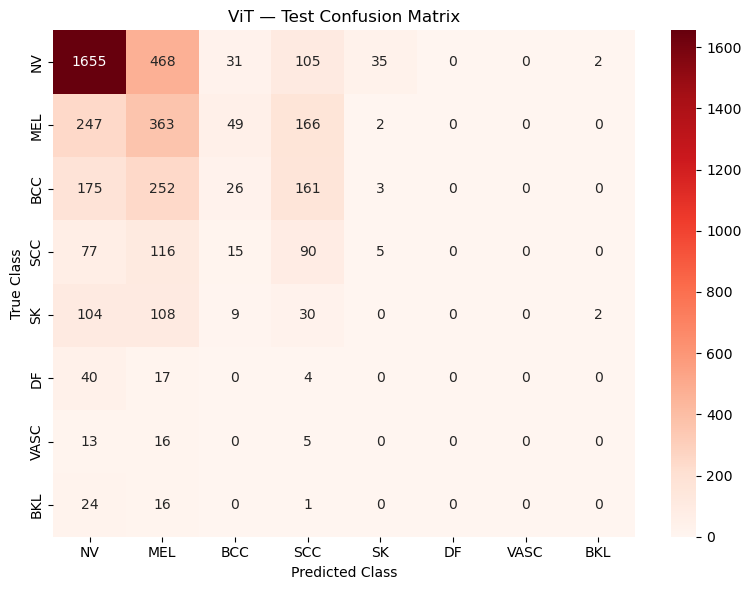


=== Vision Transformer (ViT) Classification Report ===
              precision    recall  f1-score   support

          NV     0.7088    0.7208    0.7147      2296
         MEL     0.2677    0.4389    0.3326       827
         BCC     0.2000    0.0421    0.0696       617
         SCC     0.1601    0.2970    0.2081       303
          SK     0.0000    0.0000    0.0000       253
          DF     0.0000    0.0000    0.0000        61
        VASC     0.0000    0.0000    0.0000        34
         BKL     0.0000    0.0000    0.0000        41

    accuracy                         0.4815      4432
   macro avg     0.1671    0.1874    0.1656      4432
weighted avg     0.4559    0.4815    0.4563      4432



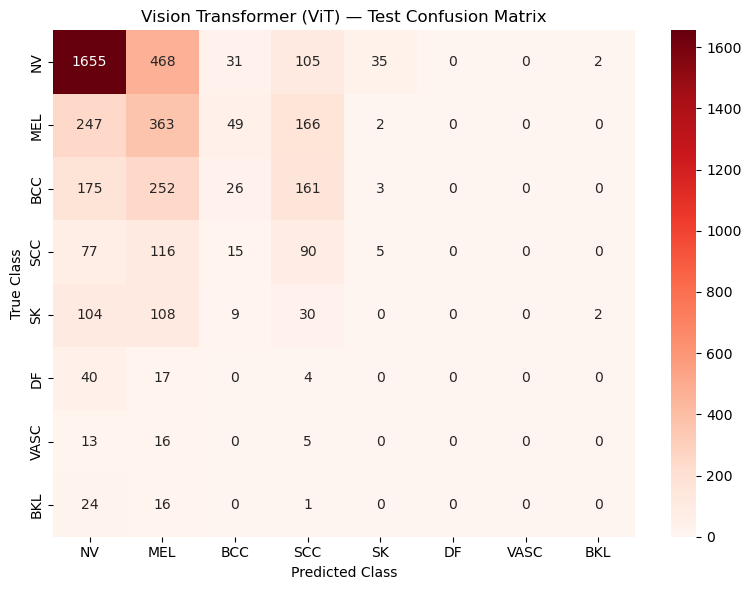


=== Vision Transformer (ViT) Evaluation by Source ===
                   Model    Source  Samples  Accuracy  Macro-F1
Vision Transformer (ViT)  BCN20000     2656  0.312500  0.136942
Vision Transformer (ViT) DERM12345     1776  0.734234  0.140804


In [48]:
# SECTION 31c: Training & Evaluation of ViT
vit_callbacks = [
    EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True), # Patience kam hai
    ModelCheckpoint(str(OUTPUT_DIR / "best_vit.keras"), monitor="val_loss", save_best_only=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-6)
]

print("Starting Vision Transformer (ViT) training... (This will take a while)")
start_vit = time.time()
vit_history = vit_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10, # Kam epochs kyunki CPU par ViT slow hai
    class_weight=cnn_weights,
    callbacks=vit_callbacks,
    verbose=1
)
vit_train_time = round(time.time() - start_vit, 2)

vit_model.save(OUTPUT_DIR / "vit_final.keras")

# Compute Validation Predictions
print("Computing ViT Validation Predictions...")
vit_val_prob = vit_model.predict(val_ds)
vit_val_pred = np.argmax(vit_val_prob, axis=1)
vit_val_true = val_df["unified_label"].map(CLASS_TO_IDX).values

# Compute Test Predictions
print("Computing ViT Test Predictions...")
vit_test_prob = vit_model.predict(test_ds)
vit_test_pred = np.argmax(vit_test_prob, axis=1)
vit_y_true    = test_df["unified_label"].map(CLASS_TO_IDX).values

test_predictions_dict["vit_pred"] = [IDX_TO_CLASS[p] for p in vit_test_pred]

# Calculate Metrics
vit_metrics = {
    "Model": "Vision Transformer (ViT)",
    "Val Accuracy": accuracy_score(vit_val_true, vit_val_pred),
    "Val Precision": precision_score(vit_val_true, vit_val_pred, average="macro", zero_division=0),
    "Val Recall": recall_score(vit_val_true, vit_val_pred, average="macro", zero_division=0),
    "Val Macro-F1": f1_score(vit_val_true, vit_val_pred, average="macro", zero_division=0),
    "Test Accuracy": accuracy_score(vit_y_true, vit_test_pred),
    "Test Precision": precision_score(vit_y_true, vit_test_pred, average="macro", zero_division=0),
    "Test Recall": recall_score(vit_y_true, vit_test_pred, average="macro", zero_division=0),
    "Test Macro-F1": f1_score(vit_y_true, vit_test_pred, average="macro", zero_division=0),
    "Train Time (sec)": vit_train_time
}

# Confusion Matrix
vit_cm = confusion_matrix(vit_y_true, vit_test_pred, labels=np.arange(NUM_CLASSES))
plt.figure(figsize=(8, 6))
sns.heatmap(vit_cm, annot=True, fmt="d", cmap="Reds", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("ViT — Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "vit_confusion_matrix.png", dpi=300)
plt.show()

# Full Evaluation
# Full Evaluation
def full_eval(name, y_true, y_pred, y_prob=None, source_labels=None):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    assert len(y_true) == len(y_pred), f"{name}: label/prediction length mismatch"

    labels = np.arange(NUM_CLASSES)

    print(f"\n=== {name} Classification Report ===")
    print(classification_report(
        y_true,
        y_pred,
        labels=labels,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Reds",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )
    plt.title(f"{name} — Test Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.tight_layout()

    safe_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    plt.savefig(OUTPUT_DIR / f"{safe_name}_confusion_matrix.png", dpi=300)
    plt.show()

    if source_labels is not None:
        source_labels = np.asarray(source_labels)
        assert len(source_labels) == len(y_true), (
            f"{name}: source label length mismatch"
        )

        source_results = []
        for source in np.unique(source_labels):
            mask = source_labels == source
            source_results.append({
                "Model": name,
                "Source": source,
                "Samples": int(mask.sum()),
                "Accuracy": accuracy_score(y_true[mask], y_pred[mask]),
                "Macro-F1": f1_score(
                    y_true[mask],
                    y_pred[mask],
                    labels=labels,
                    average="macro",
                    zero_division=0
                )
            })

        source_eval_df = pd.DataFrame(source_results)
        source_eval_df.to_csv(
            OUTPUT_DIR / f"{safe_name}_source_evaluation.csv",
            index=False
        )

        print(f"\n=== {name} Evaluation by Source ===")
        print(source_eval_df.to_string(index=False))

    return cm


full_eval(
    "Vision Transformer (ViT)",
    vit_y_true,
    vit_test_pred,
    vit_test_prob,
    source_labels=test_df["source"].values
)

# Save for final comparison
ml_results_list.append(vit_metrics)

In [51]:
# 1. Collate all model results (Adding ViT explicitly)
all_results = ml_results_list + [ann_metrics, cnn_metrics, resnet_metrics, vit_metrics]
print("\n=== FINAL MODEL COMPARISON TABLE (INCLUDING ViT) ===")
final_comparison_df = pd.DataFrame(all_results)
final_comparison_df = final_comparison_df.sort_values(by="Test Macro-F1", ascending=False)
final_comparison_df = final_comparison_df[columns_order]
final_comparison_df.to_csv(OUTPUT_DIR / "final_model_comparison_with_vit.csv", index=False)
print(final_comparison_df.to_string(index=False))


=== FINAL MODEL COMPARISON TABLE (INCLUDING ViT) ===
                   Model  Val Accuracy  Val Precision  Val Recall  Val Macro-F1  Test Accuracy  Test Precision  Test Recall  Test Macro-F1  Train Time (sec)
    CNN (EfficientNetB0)      0.545417       0.375478    0.518818      0.385515       0.564531        0.376788     0.512819       0.380064          10826.36
          CNN (ResNet50)      0.594567       0.375432    0.481177      0.392858       0.606498        0.363592     0.448121       0.377836          13915.07
    HistGradientBoosting      0.488594       0.230477    0.250179      0.233454       0.463673        0.218332     0.221189       0.213973             30.74
                     ANN      0.426172       0.242588    0.262481      0.241097       0.415839        0.217695     0.219224       0.207408             93.38
     Logistic Regression      0.332642       0.219696    0.246481      0.195898       0.313403        0.213743     0.227586       0.182541             49.38
Visi